In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

import main_analysis as ma

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/preprint/section5'
os.makedirs(PLOTS_DIR, exist_ok=True)

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [3]:
def bootstrap_ci(
    values,
    statistic="median",
    n_boot=10000,
    ci=95,
    seed=0
):
    """
    Compute bootstrap confidence interval for mean or median.

    Parameters
    ----------
    values : array-like
        1D array of values (e.g., model-level gaps).
    statistic : {"median", "mean"}
        Statistic to bootstrap.
    n_boot : int
        Number of bootstrap resamples.
    ci : float
        Confidence interval width (default 95).
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    dict with:
        - stat (observed statistic)
        - ci_low
        - ci_high
    """
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    rng = np.random.default_rng(seed)

    if statistic == "median":
        stat_fn = np.median
    elif statistic == "mean":
        stat_fn = np.mean
    else:
        raise ValueError("statistic must be 'median' or 'mean'")

    observed = stat_fn(values)

    boot_stats = []
    n = len(values)

    for _ in range(n_boot):
        sample = rng.choice(values, size=n, replace=True)
        boot_stats.append(stat_fn(sample))

    boot_stats = np.array(boot_stats)

    alpha = (100 - ci) / 2
    ci_low = np.percentile(boot_stats, alpha)
    ci_high = np.percentile(boot_stats, 100 - alpha)

    return {
        "stat": observed,
        "ci_low": ci_low,
        "ci_high": ci_high
    }

# Main figure

In [35]:
savefig = True

plot_dir = f'{PLOTS_DIR}/main_figure'
os.makedirs(plot_dir, exist_ok=True)

lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

results_df = lesion_csv.copy()
frois = ['FFA', 'EBA', 'PPA']
t_threshold = 7
mapper = 'ridge'
alpha = 0.1
subjects = [1, 2, 5, 7]
metrics = ['raw_pearsonr', 'raw_rdmr']
layer_lesion_froi_stats_df = []

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold) &
    (results_df['mapper'] == mapper) &
    (results_df['alpha'] == alpha)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
	'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'percent_units_lesioned': 'median',
    'fmri_splithalf_pearsonr': 'median',
    'fmri_splithalf_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(
    len(metrics), len(frois),
    figsize=(5*len(frois), 5*len(metrics)),
    dpi=300
)

# --- style (borrowed from your mimic code + paper figure) ---
x_offset = 0 # 0.05
pt_alpha = 0.7 # 0.6
markersize = 20 # 25
bar_width = 0.12 # 0.20

x = np.array([0.0, 0.3, 0.6])

# paper-like fills
bar_colors = ['#ffffff', '#ff0000', '#43914e']  # white, red, green
pt_color = 'gray'  # like your mimic code

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]

    # ceiling per froi
    ceiling = {
        'raw_pearsonr': results_df_froi['fmri_splithalf_pearsonr'].values[0],
        'raw_rdmr': results_df_froi['fmri_splithalf_rdmr'].values[0],
    }

    for midx, metric in enumerate(metrics):
        ax = axs[midx, fidx]

        # ceiling dashed line (match mimic code)
        ax.axhline(
            y=ceiling[metric],
            color='k', linestyle='--', alpha=0.75, linewidth=1
        )

        # collect points
        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())
        froi_pts  = np.array(results_df_froi[f'froi_{metric}'].tolist())

        # x coords (small shift left)
        x_layer  = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        x_froi   = (np.ones(len(froi_pts))  * x[2]) - x_offset

        # connect triplets (light gray, thin)
        for i in range(len(froi_pts)):
            ax.plot(
                [x_layer[i], x_lesion[i], x_froi[i]],
                [layer_pts[i], lesion_pts[i], froi_pts[i]],
                color='0.6', alpha=0.25, linewidth=0.7, zorder=1
            )

        # If you want open circles instead (closer to the screenshot),
        # replace the three scatters above with facecolors='none' and set alpha=1.

        # bars: median ± SEM (paper style)
        pts_list = [layer_pts, lesion_pts, froi_pts]
        medians = [np.median(p) for p in pts_list]
        # sems = [np.std(p, ddof=1) / np.sqrt(len(p)) for p in pts_list]

        # ax.bar(
        #     x, medians,
        #     yerr=sems,
        #     width=bar_width,
        #     color=bar_colors,
        #     alpha=1,
        #     capsize=0,
        #     edgecolor='k',
        #     linewidth=1.0,
        #     error_kw={'linewidth': 1.0, 'ecolor': 'k'},
        #     zorder=0
        # )

        box = ax.boxplot(
            pts_list,
            positions=x,
            widths=bar_width,
            patch_artist=True,
            showfliers=False,
            medianprops=dict(color='k', linewidth=1.5),
            boxprops=dict(linewidth=1.2, edgecolor='k'),
            whiskerprops=dict(linewidth=1.2, color='k'),
            capprops=dict(linewidth=1.2, color='k'),
        )

        # color the boxes
        for patch, color in zip(box['boxes'], bar_colors):
            patch.set_facecolor(color)
        
        for i, data in enumerate(box['medians']):
            med = medians[i]
            # Manually draw a longer median line
            x_ = x[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x_ - 0.1, x_ + 0.1], [med, med], color='black', linewidth=1.2, solid_capstyle='butt')
        
        # scatter points (inspired by your mimic)
        # Option A (closer to mimic): gray filled w/ black edge
        ax.scatter(x_layer,  layer_pts,  color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.7)
        ax.scatter(x_lesion, lesion_pts, color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.7)
        ax.scatter(x_froi,   froi_pts,   color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.7)

        # % lesioned text (keep your original behavior)
        # percent_lesioned_list = results_df_froi['percent_units_lesioned'].values
        # pl_mean = np.mean(percent_lesioned_list)
        # pl_sem = np.std(percent_lesioned_list, ddof=1) / np.sqrt(len(percent_lesioned_list))
        # ax.text(
        #     x[-1], 0.95,
        #     f"{pl_mean:.1f} ± {pl_sem:.1f}%",
        #     ha='center', va='bottom',
        #     fontsize=11, color='black', alpha=0.85
        # )

        # fROI label (bold, like your mimic)
        if metric == 'raw_pearsonr':
            ax.text(
                0.15, 0.85, froi,
                ha='right', va='bottom',
                transform=ax.transAxes,
                fontsize=16, fontweight='bold'
            )
        else:
            ax.text(
                0.15, 0.65, froi,
                ha='right', va='bottom',
                transform=ax.transAxes,
                fontsize=16, fontweight='bold'
            )

        # baseline at 0
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        # cosmetic spines/ticks (match mimic)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))

        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
        ax.spines['left'].set_bounds(0, 1)
        ax.spines['bottom'].set_bounds(x[0], x[-1])
        ax.set_xlim(x[0]-0.25, x[-1]+0.25)

        ax.set_xticks(x, ['all\nunits', 'lesioned', 'only category-selective\nunits'], fontsize=10)

        # optional: add "lesioned" bracket-ish label under first two bars (paper-like)
        # ax.text(
        #     (x[0]+x[1])/2, -0.18, "lesioned",
        #     ha='center', va='top',
        #     transform=ax.get_xaxis_transform(),
        #     fontsize=11
        # )

        # labels: only leftmost y, only bottom x
        if fidx == 0:
            if 'pearsonr' in metric:
                ax.set_ylabel('univariate', fontsize=12)
            else:
                ax.set_ylabel('multivariate', fontsize=12)
        else:
            ax.spines['left'].set_visible(False)
            ax.yaxis.set_ticks([])
            ax.set_ylabel('')

        # if midx == len(metrics) - 1:
        ax.set_xlabel('ANN unit subset', fontsize=12)
        # else:
        #     ax.set_xlabel('')

fig.supylabel(r"Prediction accuracy, $R$", fontsize=14)
plt.tight_layout()

if savefig:
    plt.savefig(
        f'{plot_dir}/fig5_lesioning_EMs.pdf',
        dpi=300, bbox_inches='tight', transparent=True
    )
else:
    plt.show()
plt.close()

In [18]:
for froi in frois:
    print(f"fROI: {froi}")
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    display(results_df_froi[
        (results_df_froi['froi_raw_pearsonr'] > results_df_froi['layer_raw_pearsonr'])
    ])
    display(results_df_froi[
        (results_df_froi['froi_raw_rdmr'] > results_df_froi['layer_raw_rdmr'])
    ])
    print("\n\n")

fROI: FFA


,model,fmri_froi,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr,percent_units_lesioned,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
7,alexnetipclref01,FFA,0.478719,0.165016,0.528302,0.219914,0.459523,0.147488,3.700536,0.811307,0.549919
58,resnet50simclr,FFA,0.654766,0.339513,0.656403,0.420194,0.645608,0.316684,7.617188,0.811307,0.549919


,model,fmri_froi,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr,percent_units_lesioned,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
7,alexnetipclref01,FFA,0.478719,0.165016,0.528302,0.219914,0.459523,0.147488,3.700536,0.811307,0.549919
58,resnet50simclr,FFA,0.654766,0.339513,0.656403,0.420194,0.645608,0.316684,7.617188,0.811307,0.549919





fROI: EBA


,model,fmri_froi,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr,percent_units_lesioned,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
21,resnet101imagenet1kv1,EBA,0.586273,0.331596,0.632678,0.397618,0.579921,0.324443,3.662109,0.772388,0.536985
57,resnet50simclr,EBA,0.655751,0.383332,0.698970,0.482774,0.649023,0.356583,2.441406,0.772388,0.536985
60,resnet50sin,EBA,0.538735,0.249808,0.545222,0.278091,0.540041,0.249767,1.220703,0.772388,0.536985
63,resnet50toponettau30,EBA,0.612834,0.332180,0.655665,0.453059,0.600844,0.316707,4.492188,0.772388,0.536985


,model,fmri_froi,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr,percent_units_lesioned,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
21,resnet101imagenet1kv1,EBA,0.586273,0.331596,0.632678,0.397618,0.579921,0.324443,3.662109,0.772388,0.536985
36,resnet50blurstrong,EBA,0.586872,0.262335,0.583229,0.309746,0.586229,0.258897,1.806641,0.772388,0.536985
57,resnet50simclr,EBA,0.655751,0.383332,0.698970,0.482774,0.649023,0.356583,2.441406,0.772388,0.536985
60,resnet50sin,EBA,0.538735,0.249808,0.545222,0.278091,0.540041,0.249767,1.220703,0.772388,0.536985
63,resnet50toponettau30,EBA,0.612834,0.332180,0.655665,0.453059,0.600844,0.316707,4.492188,0.772388,0.536985





fROI: PPA


,model,fmri_froi,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr,percent_units_lesioned,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
38,resnet50blurstrong,PPA,0.572408,0.243280,0.654731,0.343329,0.568335,0.239237,3.906250,0.771785,0.471653
65,resnet50toponettau30,PPA,0.618251,0.280587,0.639946,0.334358,0.606543,0.260648,4.541016,0.771785,0.471653


,model,fmri_froi,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr,percent_units_lesioned,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
38,resnet50blurstrong,PPA,0.572408,0.243280,0.654731,0.343329,0.568335,0.239237,3.906250,0.771785,0.471653
65,resnet50toponettau30,PPA,0.618251,0.280587,0.639946,0.334358,0.606543,0.260648,4.541016,0.771785,0.471653


## Legacy: Bar plots

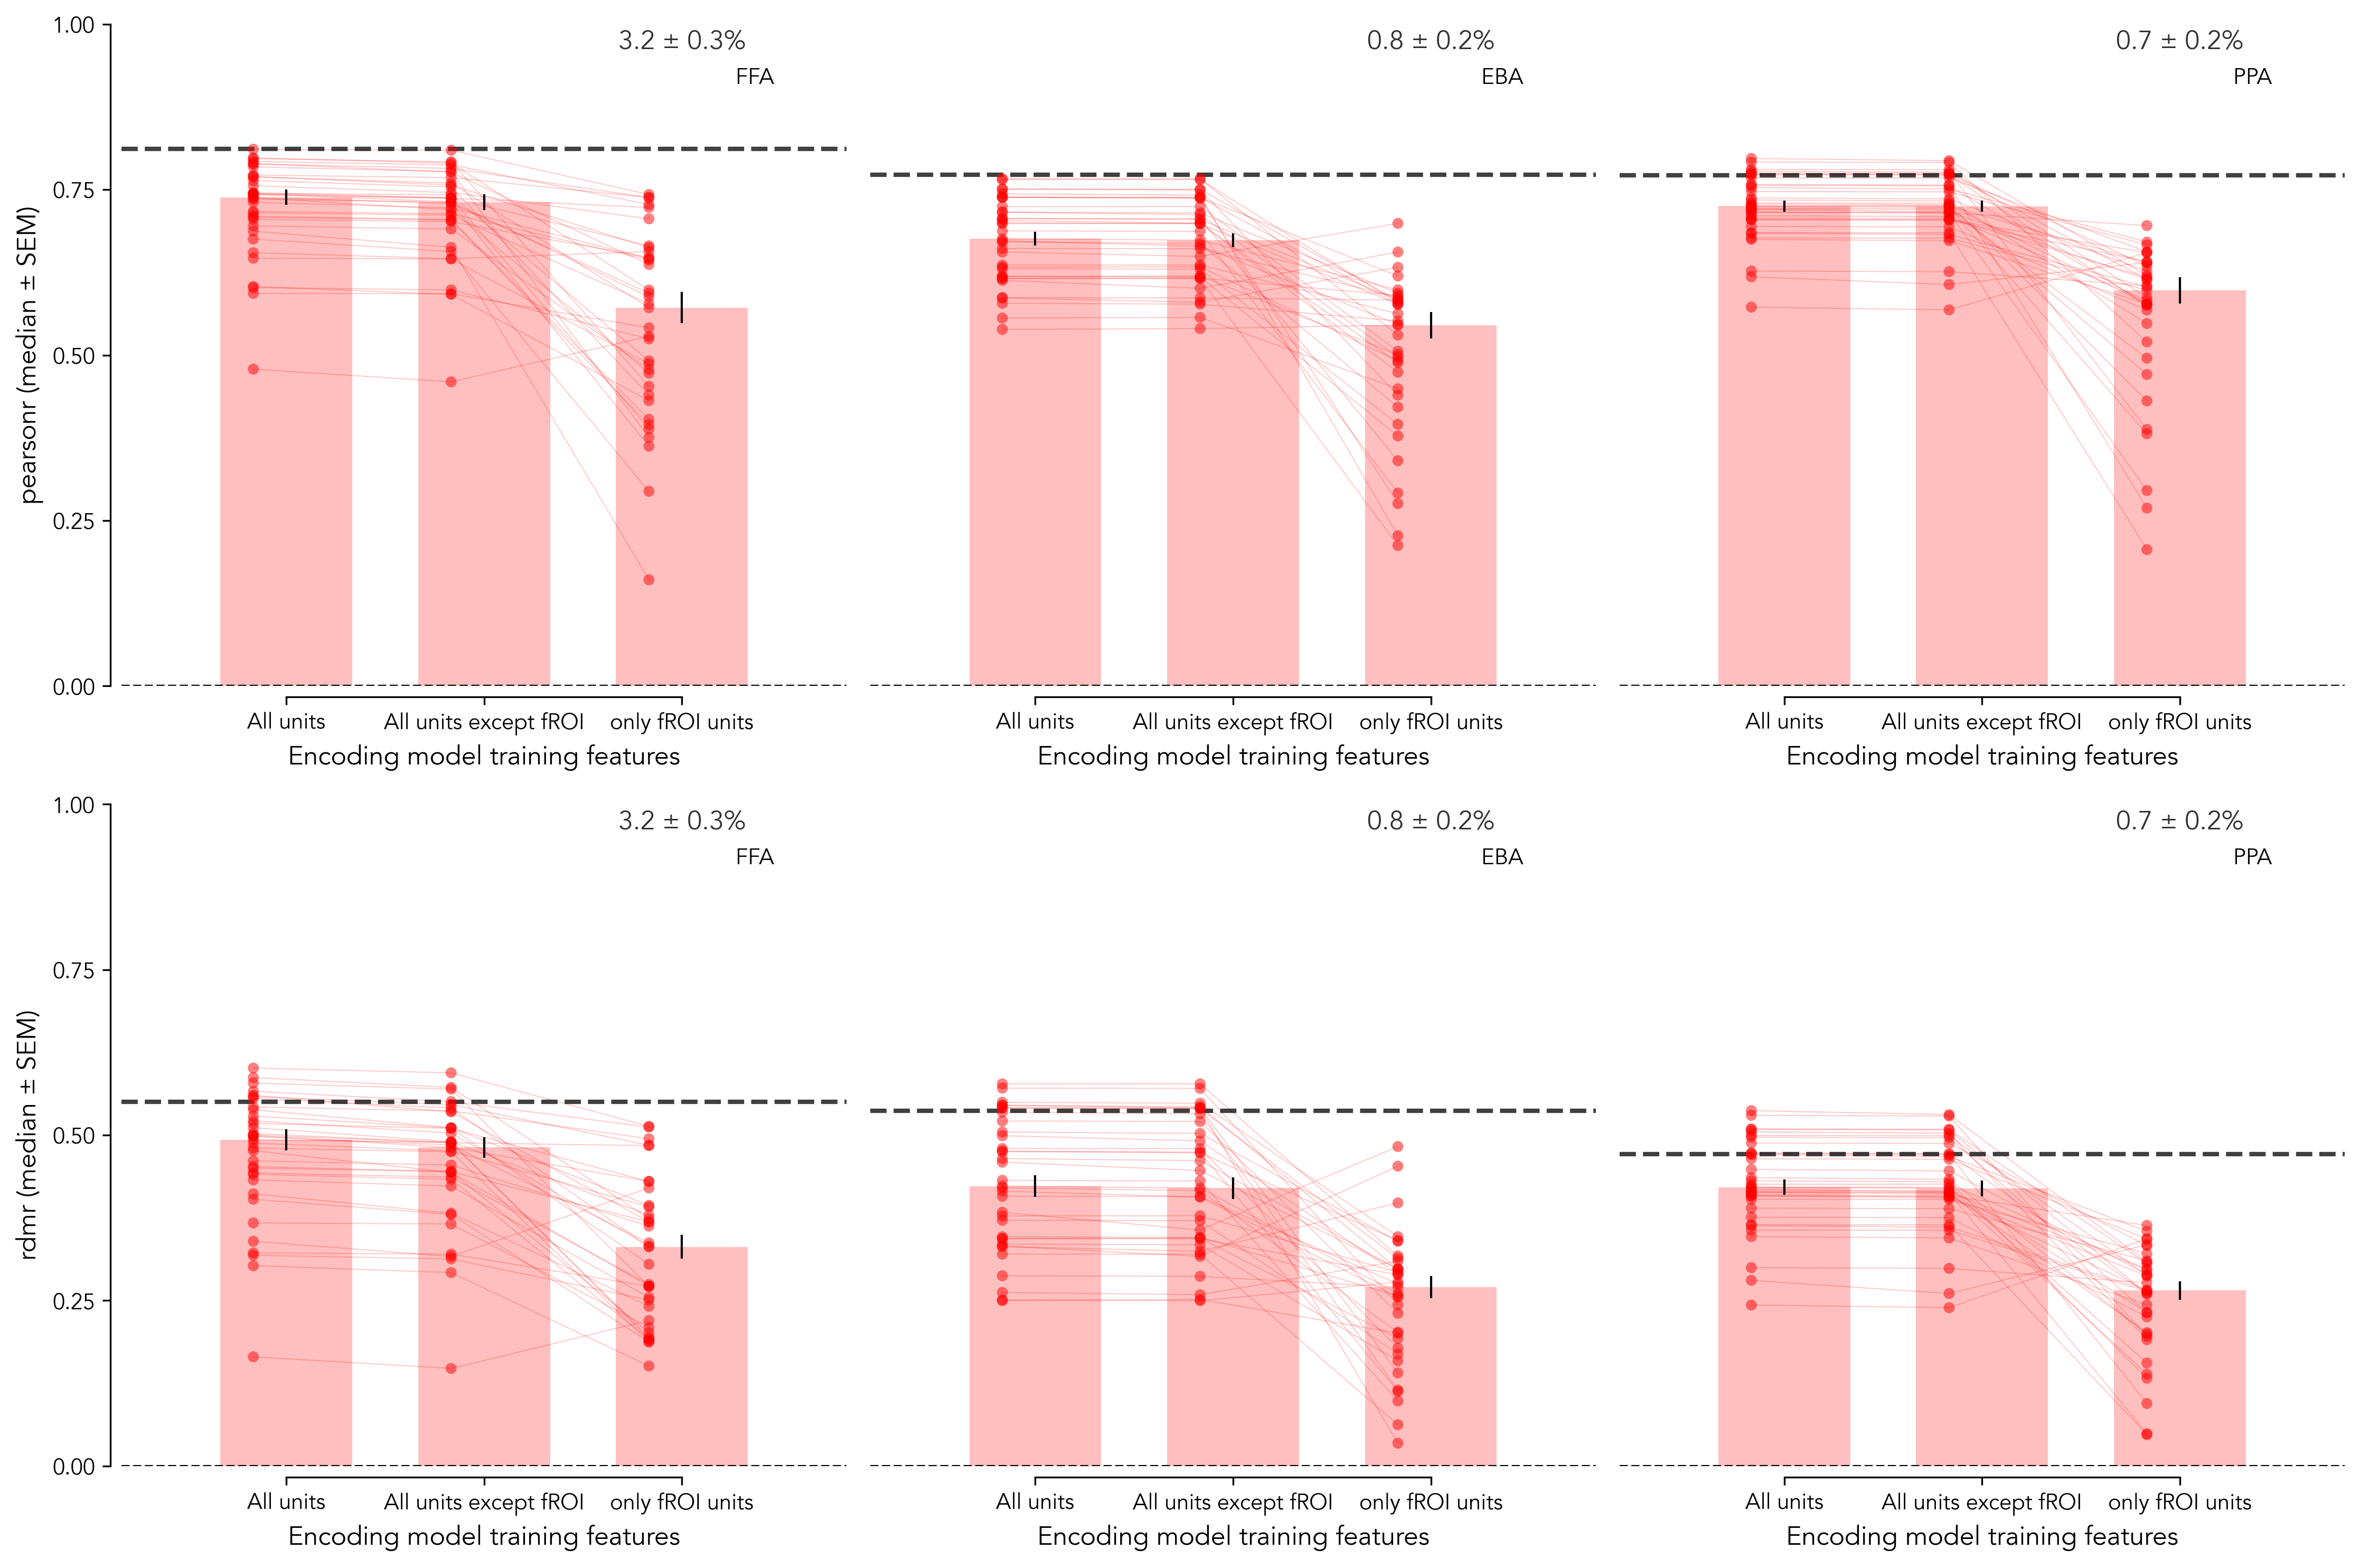

,froi,metric,layer_norm_pvalue,froi_norm_pvalue,lesion_norm_pvalue,layer_lesion_tvalue,layer_lesion_pvalue,layer_froi_tvalue,layer_froi_pvalue,layer_lesion_wstat,layer_lesion_pvalue_w,layer_froi_wstat,layer_froi_pvalue_w
0,FFA,raw_pearsonr,0.000928,0.156163,0.000883,8.325304,1.020031e-09,7.513631,1.009694e-08,0.0,5.820766e-11,5.0,5.820766e-10
1,FFA,raw_rdmr,0.008910,0.074231,0.007283,9.756830,2.182899e-11,8.937971,1.905756e-10,0.0,5.820766e-11,14.0,6.402843e-09
2,EBA,raw_pearsonr,0.171718,0.009189,0.197673,3.373798,1.864653e-03,7.074053,3.600897e-08,101.0,2.429703e-04,20.0,2.159504e-08
3,EBA,raw_rdmr,0.092036,0.621553,0.093221,3.495289,1.338134e-03,6.963401,4.973870e-08,30.0,1.184526e-07,30.0,1.184526e-07
4,PPA,raw_pearsonr,0.028364,0.000043,0.014339,3.575774,1.071629e-03,7.282786,1.964002e-08,19.0,1.786975e-08,11.0,3.201421e-09
5,PPA,raw_rdmr,0.207176,0.016968,0.098129,3.368927,1.889451e-03,9.328540,6.706495e-11,11.0,3.201421e-09,11.0,3.201421e-09


In [2]:
savefig = False

lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

plot_dir = f'{PLOTS_DIR}/main_figure'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
frois = ['FFA', 'EBA', 'PPA']
t_threshold = 7
mapper = 'ridge'
alpha = 0.1
subjects = [1, 2, 5, 7]
metrics = ['raw_pearsonr', 'raw_rdmr']
layer_lesion_froi_stats_df = []

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold) &
    (results_df['mapper'] == mapper) &
    (results_df['alpha'] == alpha)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
	'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'percent_units_lesioned': 'median',
    'fmri_splithalf_pearsonr': 'median',
    'fmri_splithalf_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    # Get fmri_splithalf_pearsonr, fmri_splithalf_rdmr from the first row
    ceiling = {
        'raw_pearsonr': results_df_froi['fmri_splithalf_pearsonr'].values[0],
        'raw_rdmr': results_df_froi['fmri_splithalf_rdmr'].values[0],
    }
    for midx, metric in enumerate(metrics):
        # Plot ceiling as a horizontal line
        axs[midx, fidx].axhline(y=ceiling[metric], color='k', linestyle='--', alpha=0.75, linewidth=2)

        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        froi_pts = np.array(results_df_froi[f'froi_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())

        x_layer = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        x_froi = (np.ones(len(froi_pts)) * x[2]) - x_offset
        axs[midx, fidx].scatter(
            x_layer, layer_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(froi_pts)):
            axs[midx, fidx].plot(
                [x_layer[i], x_lesion[i], x_froi[i]], 
                [layer_pts[i], lesion_pts[i], froi_pts[i]], 
                color='red', alpha=0.2, linewidth=0.5, zorder=1
            )

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(layer_pts), np.median(lesion_pts), np.median(froi_pts)]
        sems = [
            layer_pts.std() / np.sqrt(len(layer_pts)),
            lesion_pts.std() / np.sqrt(len(lesion_pts)),
            froi_pts.std() / np.sqrt(len(froi_pts)),
        ]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        # Stats
        # test normality
        layer_norm_pvalue = scipy.stats.shapiro(layer_pts)[1]
        froi_norm_pvalue = scipy.stats.shapiro(froi_pts)[1]
        lesion_norm_pvalue = scipy.stats.shapiro(lesion_pts)[1]
        # Conduct Welch's t-test
        layer_lesion_tvalue, layer_lesion_pvalue = scipy.stats.ttest_rel(
            layer_pts, lesion_pts, alternative='two-sided'
        )
        layer_froi_tvalue, layer_froi_pvalue = scipy.stats.ttest_rel(
            layer_pts, froi_pts, alternative='two-sided'
        )
        # Conduct Wilcoxon signed-rank test
        layer_lesion_wstat, layer_lesion_pvalue_w = scipy.stats.wilcoxon(
            layer_pts, lesion_pts, alternative='two-sided'
        )
        layer_froi_wstat, layer_froi_pvalue_w = scipy.stats.wilcoxon(
            layer_pts, froi_pts, alternative='two-sided'
        )
        # Store stats
        layer_lesion_stats = {
            'froi': froi,
            'metric': metric,
            'layer_norm_pvalue': layer_norm_pvalue,
            'froi_norm_pvalue': froi_norm_pvalue,
            'lesion_norm_pvalue': lesion_norm_pvalue,
            'layer_lesion_tvalue': layer_lesion_tvalue,
            'layer_lesion_pvalue': layer_lesion_pvalue,
            'layer_froi_tvalue': layer_froi_tvalue,
            'layer_froi_pvalue': layer_froi_pvalue,
            'layer_lesion_wstat': layer_lesion_wstat,
            'layer_lesion_pvalue_w': layer_lesion_pvalue_w,
            'layer_froi_wstat': layer_froi_wstat,
            'layer_froi_pvalue_w': layer_froi_pvalue_w,
        }
        layer_lesion_froi_stats_df.append(layer_lesion_stats)

        # Get % units lesioned for this froi
        percent_lesioned_list = results_df_froi['percent_units_lesioned']
        pl_mean = np.mean(percent_lesioned_list)
        pl_sem = percent_lesioned_list.std() / np.sqrt(len(percent_lesioned_list))
        axs[midx, fidx].text(
                x[-1], 0.95,
                f"{pl_mean:.1f} ± {pl_sem:.1f}%",
                horizontalalignment='center', verticalalignment='bottom',
                fontsize=12, color='black', alpha=0.8
            )

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        axs[midx, fidx].set_xticks(x, ['All units', 'All units except fROI', 'only fROI units'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'{metric.split("_")[-1]} (median ± SEM)', fontsize=12)
        axs[midx, fidx].set_xlabel(f'Encoding model training features', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

plt.tight_layout()
if savefig:
    raise NotImplementedError("Update filename if you want to save")
    plt.savefig(f'{plot_dir}/fig5_allunitsEM_froilesionedEM_froionlyEM.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

layer_lesion_froi_stats_df = pd.DataFrame(layer_lesion_froi_stats_df)
display(layer_lesion_froi_stats_df)

# Supplementary figures

## Fig S9: Lesioning across across ANN t-thresholds

raw_pearsonr FFA
raw_pearsonr EBA
raw_pearsonr PPA
raw_rdmr FFA
raw_rdmr EBA
raw_rdmr PPA


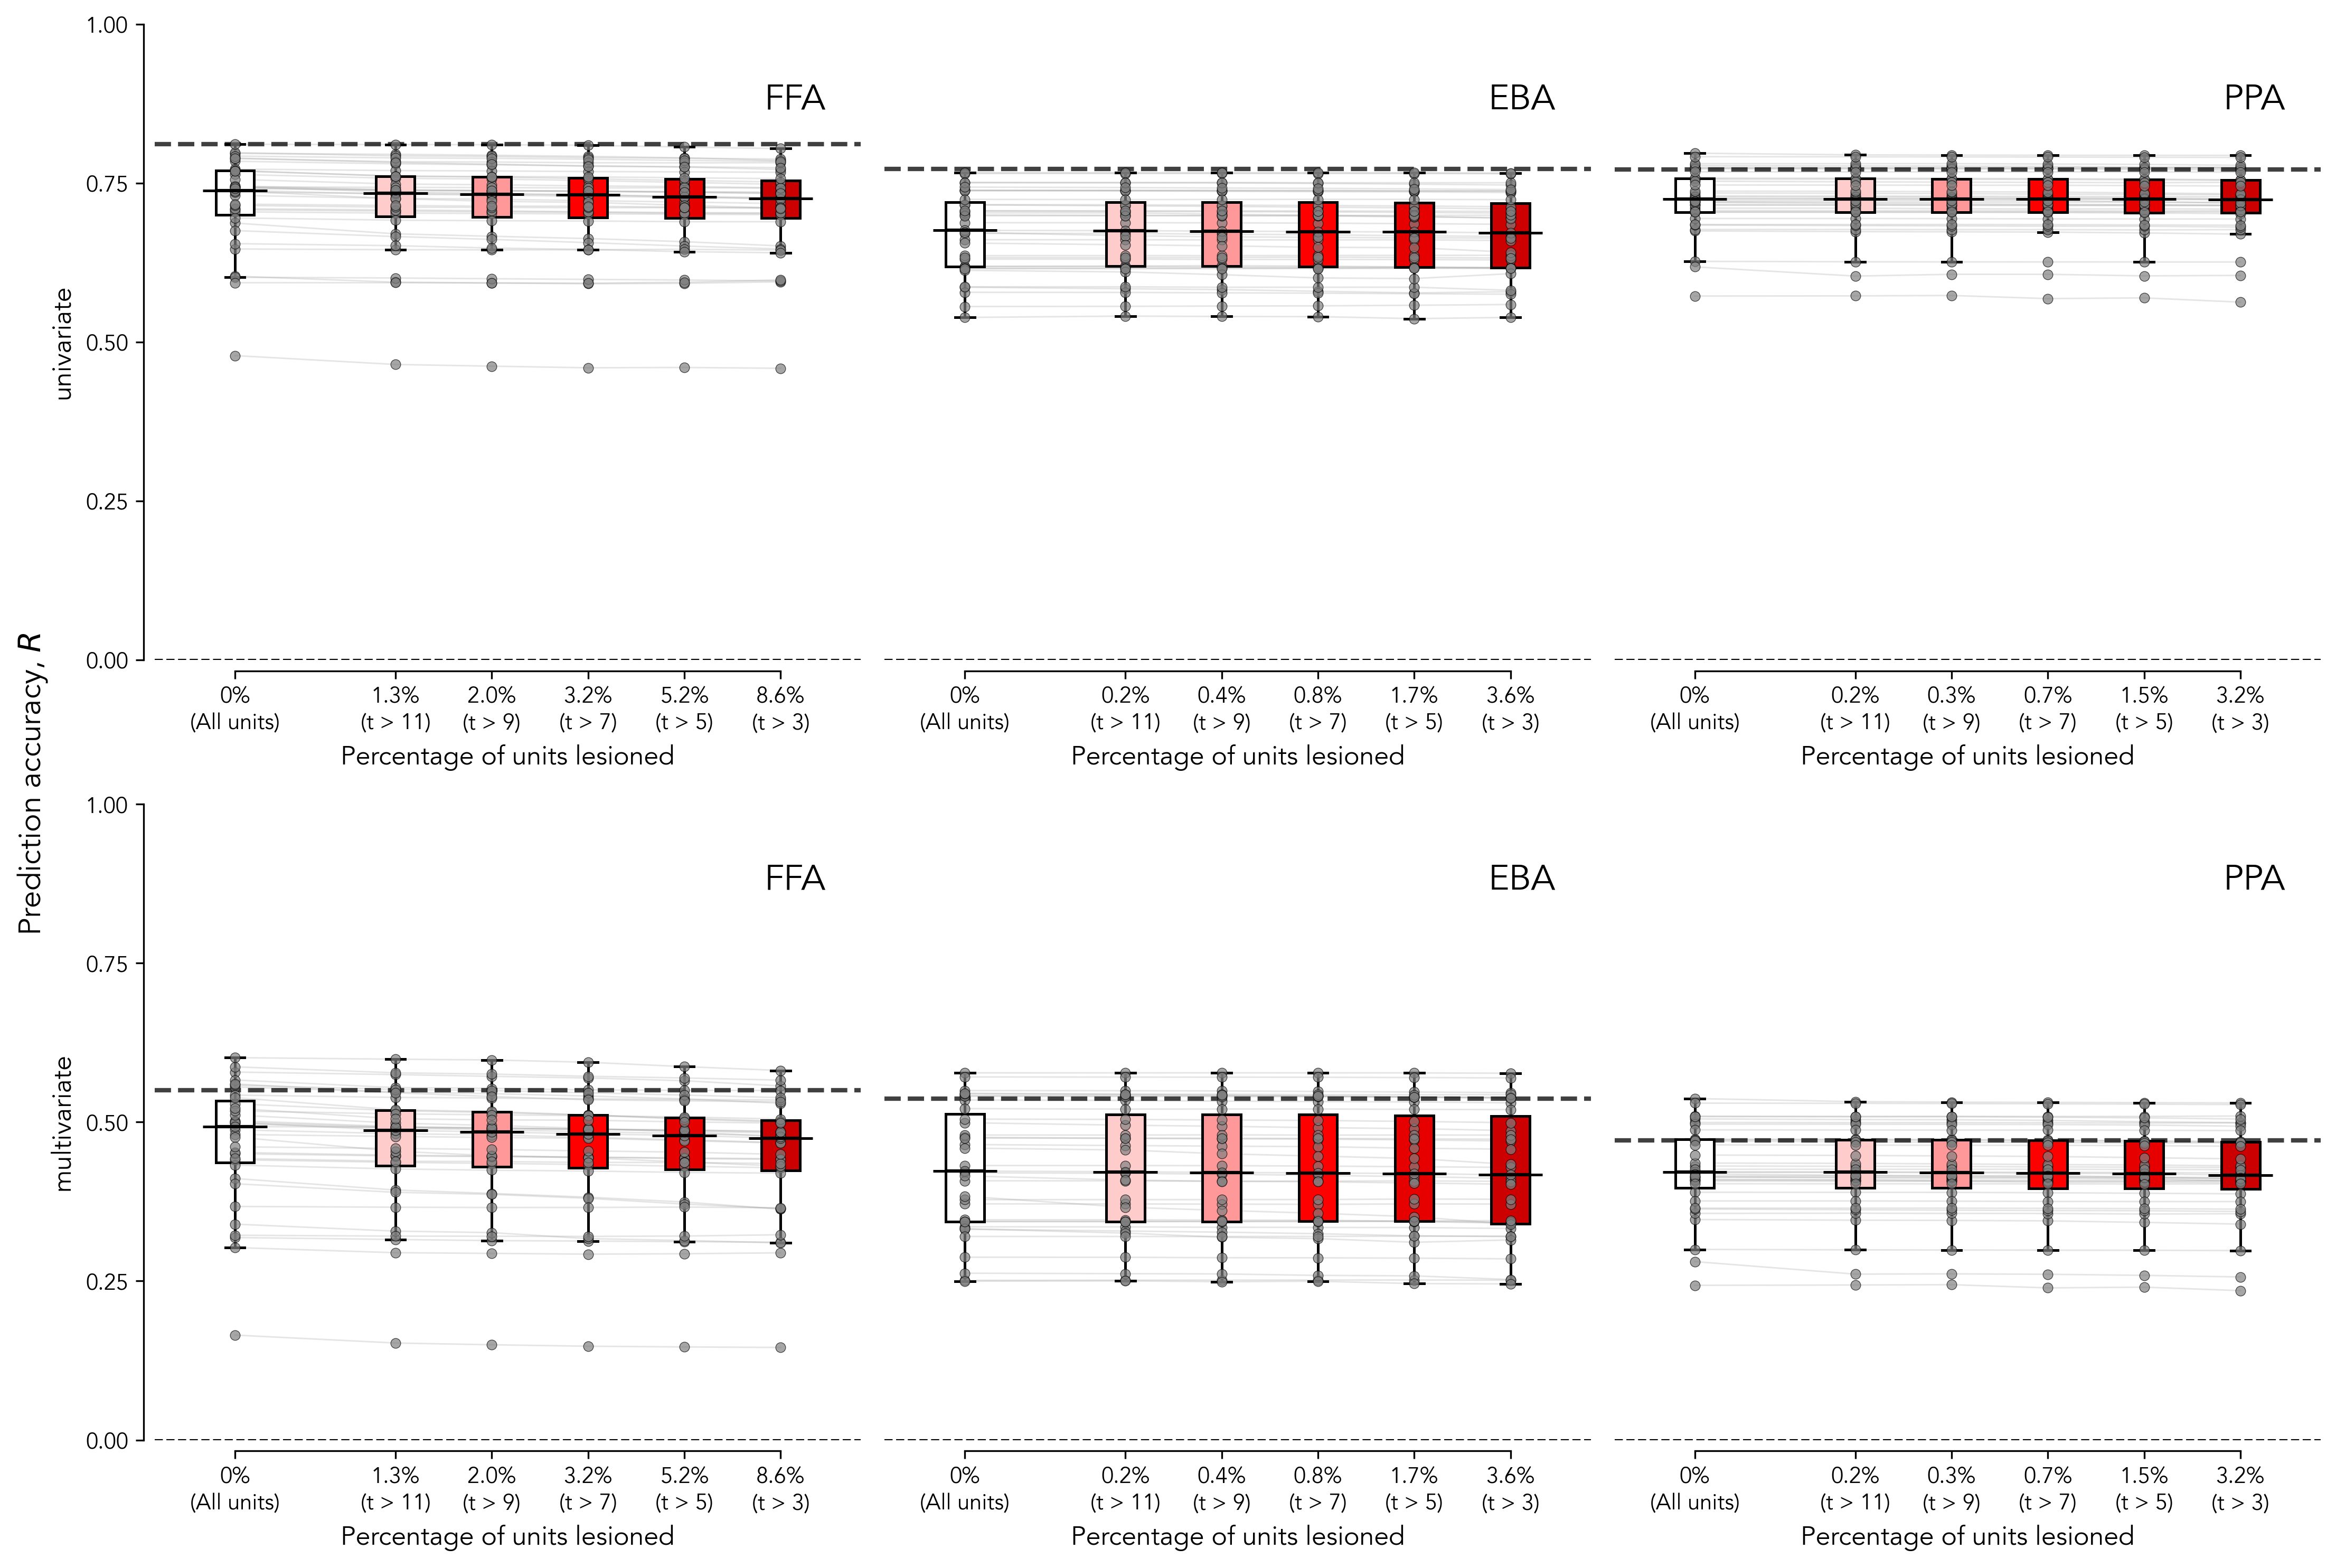

In [33]:
savefig = True

plot_dir = f'{PLOTS_DIR}/supplementary_figures'
os.makedirs(plot_dir, exist_ok=True)

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

fmri_tthreshold = 7

results_df = lesion_csv.copy()
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
subjects = results_df['subject'].unique().tolist()

frois = ['FFA', 'EBA', 'PPA']
ordered_tthresholds = [-1, 11, 9, 7, 5, 3]
xticks_dict = {
    -1: 'Intact',
    11: '11',
    9: '9',
    7: '7',
    5: '5',
    3: '3'
}
metrics = ['raw_pearsonr', 'raw_rdmr']
plot_ceiling = True

x_offset = 0 # 0.05
pt_alpha = 0.7 # 0.6
markersize = 20 # 25
bar_width = 0.12 # 0.20
x = [-0.2, 0.3, 0.6, 0.9, 1.2, 1.5]
fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

colors = [
    '#ffffff',  # white for intact
    '#ffcccc',  # very light red
    '#ff9999',  # light red
    '#ff0000',  # pure red (middle)
    '#e60000',  # slightly darker red
    '#cc0000',  # darker red
]

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        print(metric, froi)
        # For specific froi & fmri_tthreshold, get results_df
        results_df_froi = results_df[
            (results_df['model_froi'] == froi) &
            (results_df['fmri_froi'] == froi) &
            (results_df['fmri_tthreshold'] == fmri_tthreshold)
        ]
        # Take median across subjects for each model, model_threshold
        results_df_froi_sbjmedian = results_df_froi.groupby(
            ['model', 'model_tthreshold']
        ).agg({
            'raw_pearsonr': 'median',
            'normed_pearsonr': 'median',
            'raw_rdmr': 'median',
            'normed_rdmr': 'median',
            'n_units_layer': 'mean',
            'n_units_lesioned': 'mean',
            'percent_units_lesioned': 'mean',
            'fmri_splithalf_pearsonr': 'median',
            'fmri_splithalf_rdmr': 'median',
        }).reset_index()

        if plot_ceiling:
            metric_str = 'fmri_splithalf_' + metric.replace('raw_', '')
            axs[midx, fidx].axhline(
                y=results_df_froi_sbjmedian[metric_str].values[0],
                color='k', linestyle='--', alpha=0.75, linewidth=2
            )
            # ceiling_values = []
            # for subject1_idx in range(len(subjects)):
            #     for subject2_idx in range(subject1_idx, len(subjects)):
            #         subject1 = subjects[subject1_idx]
            #         subject2 = subjects[subject2_idx]
            #         if subject1 == subject2:
            #             continue
            #         subjectsubject_froi = subjectsubject_correlations_csv[
            #             (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            #             (subjectsubject_correlations_csv['subject1'] == subject1) &
            #             (subjectsubject_correlations_csv['subject2'] == subject2) & 
            #             (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
            #         ]
            #         ceiling_metric_ = 'pearsonr' if metric == 'raw_pearsonr' else metric
            #         ceiling_values += list(subjectsubject_froi[ceiling_metric_])
            #         # print(f'Subject {subject1} vs Subject {subject2}: {subjectsubject_froi[ceiling_metric]}')
            # ceiling_values = np.array(ceiling_values).flatten()
            # # print(f'Ceiling values: {ceiling_values}')
            # ceiling_median = np.median(ceiling_values)
            # ceiling_sem = np.std(ceiling_values) / np.sqrt(len(ceiling_values))

            # # Plot horizontal line at median of ceiling values
            # plt.axhline(y=ceiling_median, color='royalblue', linestyle='-', alpha=0.8, linewidth=1, zorder=1)

            # Fill area around the line for SEM
            # plt.fill_between(
            #     [x[0]-0.5, x[1]+0.5],  # Extend across full x range
            #     ceiling_median - ceiling_sem,
            #     ceiling_median + ceiling_sem,
            #     color='royalblue', alpha=0.2, zorder=0, edgecolor='none'
            # )

        
        # model_tthresholds = results_df_froi_sbjmedian['model_tthreshold'].unique()
        model_tthresholds = ordered_tthresholds
        assert set(model_tthresholds) == set(ordered_tthresholds), \
            f"Model tthresholds {model_tthresholds} are same as ordered tthresholds {ordered_tthresholds}"
        n_model_tthresholds = len(model_tthresholds)

        # percent_lesioned_means = []
        # percent_lesioned_sems = []

        # one row per model, one column per threshold, values = metric
        model_by_threshold = (
            results_df_froi_sbjmedian
            .pivot(index='model', columns='model_tthreshold', values=metric)
            .reindex(columns=model_tthresholds)
        )

        # connect points across consecutive boxes for each model
        for _, row in model_by_threshold.iterrows():
            y_line = row.values.astype(float)
            valid = ~np.isnan(y_line)

            # draw line only through available thresholds, in order
            axs[midx, fidx].plot(
                np.array(x)[valid],
                y_line[valid],
                color='0.6',
                alpha=0.25,
                linewidth=0.7,
                zorder=1
            )

        xticklabels = []

        for tidx, model_tthreshold in enumerate(model_tthresholds):
            tthreshold_results = results_df_froi_sbjmedian[
                results_df_froi_sbjmedian['model_tthreshold'] == model_tthreshold
            ].copy()

            # keep model order consistent with the lines above
            tthreshold_results = tthreshold_results.set_index('model').reindex(model_by_threshold.index).reset_index()

            y_pts = tthreshold_results[metric].values
            percent_lesioneds = tthreshold_results['percent_units_lesioned'].values

            pl_mean = np.nanmean(percent_lesioneds)
            pl_sem = np.nanstd(percent_lesioneds) / np.sqrt(np.sum(~np.isnan(percent_lesioneds)))

            if model_tthreshold == -1:
                xticklabels.append('0%\n(All units)')
            else:
                xticklabels.append(f"{pl_mean:.1f}%\n(t > {model_tthreshold})")

            median = np.nanmedian(y_pts)

            box = axs[midx, fidx].boxplot(
                [y_pts[~np.isnan(y_pts)]],          # <- wrap in list
                positions=[x[tidx]],
                widths=bar_width,
                patch_artist=True,
                showfliers=False,
                medianprops=dict(color='k', linewidth=1.5),
                boxprops=dict(linewidth=1.2, edgecolor='k'),
                whiskerprops=dict(linewidth=1.2, color='k'),
                capprops=dict(linewidth=1.2, color='k'),
            )

            # color the single box
            box['boxes'][0].set_facecolor(colors[tidx])

            # optional: longer median line
            axs[midx, fidx].plot(
                [x[tidx] - 0.1, x[tidx] + 0.1],
                [median, median],
                color='black',
                linewidth=1.2,
                solid_capstyle='butt',
                zorder=3
            )

            x_froi = np.ones(np.sum(~np.isnan(y_pts))) * x[tidx] - x_offset
            axs[midx, fidx].scatter(
                x_froi,
                y_pts[~np.isnan(y_pts)],
                color='gray',
                alpha=pt_alpha,     # not alpha=alpha
                zorder=2,
                edgecolors='k',
                linewidths=0.3,
                s=markersize
            )
            
            # # Conduct Welch's t-test
            # t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
            # # axs[midx, fidx].text(0.95, 0.89,
            # #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
            # #          horizontalalignment='right', verticalalignment='bottom',
            # #          transform=axs[midx, fidx].transAxes)
            # print(f"t-value: {t_value:.2f}\np-value: {p_value:.2e}")
        axs[midx, fidx].text(0.95, 0.85,
                    froi,
                    horizontalalignment='right', verticalalignment='bottom',
                    transform=axs[midx, fidx].transAxes, fontsize=16, fontweight='bold')

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        axs[midx, fidx].set_ylim(0, 1)
        # axs[midx, fidx].tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        # xticklabels = [xticks_dict[t] for t in model_tthresholds]
        axs[midx, fidx].set_xticks(x, xticklabels, fontsize=10)
        # axs[midx, fidx].xticks(x, model_tthresholds)
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # axs[midx, fidx].tick_params(axis='x', labelbottom=False)
        axs[midx, fidx].set_xlabel('Percentage of units lesioned', fontsize=12)
        if 'pearsonr' in metric:
            axs[midx, fidx].set_ylabel(f'univariate', fontsize=12)
        elif 'rdmr' in metric:
            axs[midx, fidx].set_ylabel(f'multivariate', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')
        # plt.title(f'{froi} fROI, mapper: Ridge', fontsize=14, pad=10)

fig.supylabel(r"Prediction accuracy, $R$", fontsize=14)
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/figS9_EMlesions_acrosstthresholds.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
plt.close()

### Legacy: Bar plots

raw_pearsonr FFA
raw_pearsonr EBA
raw_pearsonr PPA
raw_rdmr FFA
raw_rdmr EBA
raw_rdmr PPA


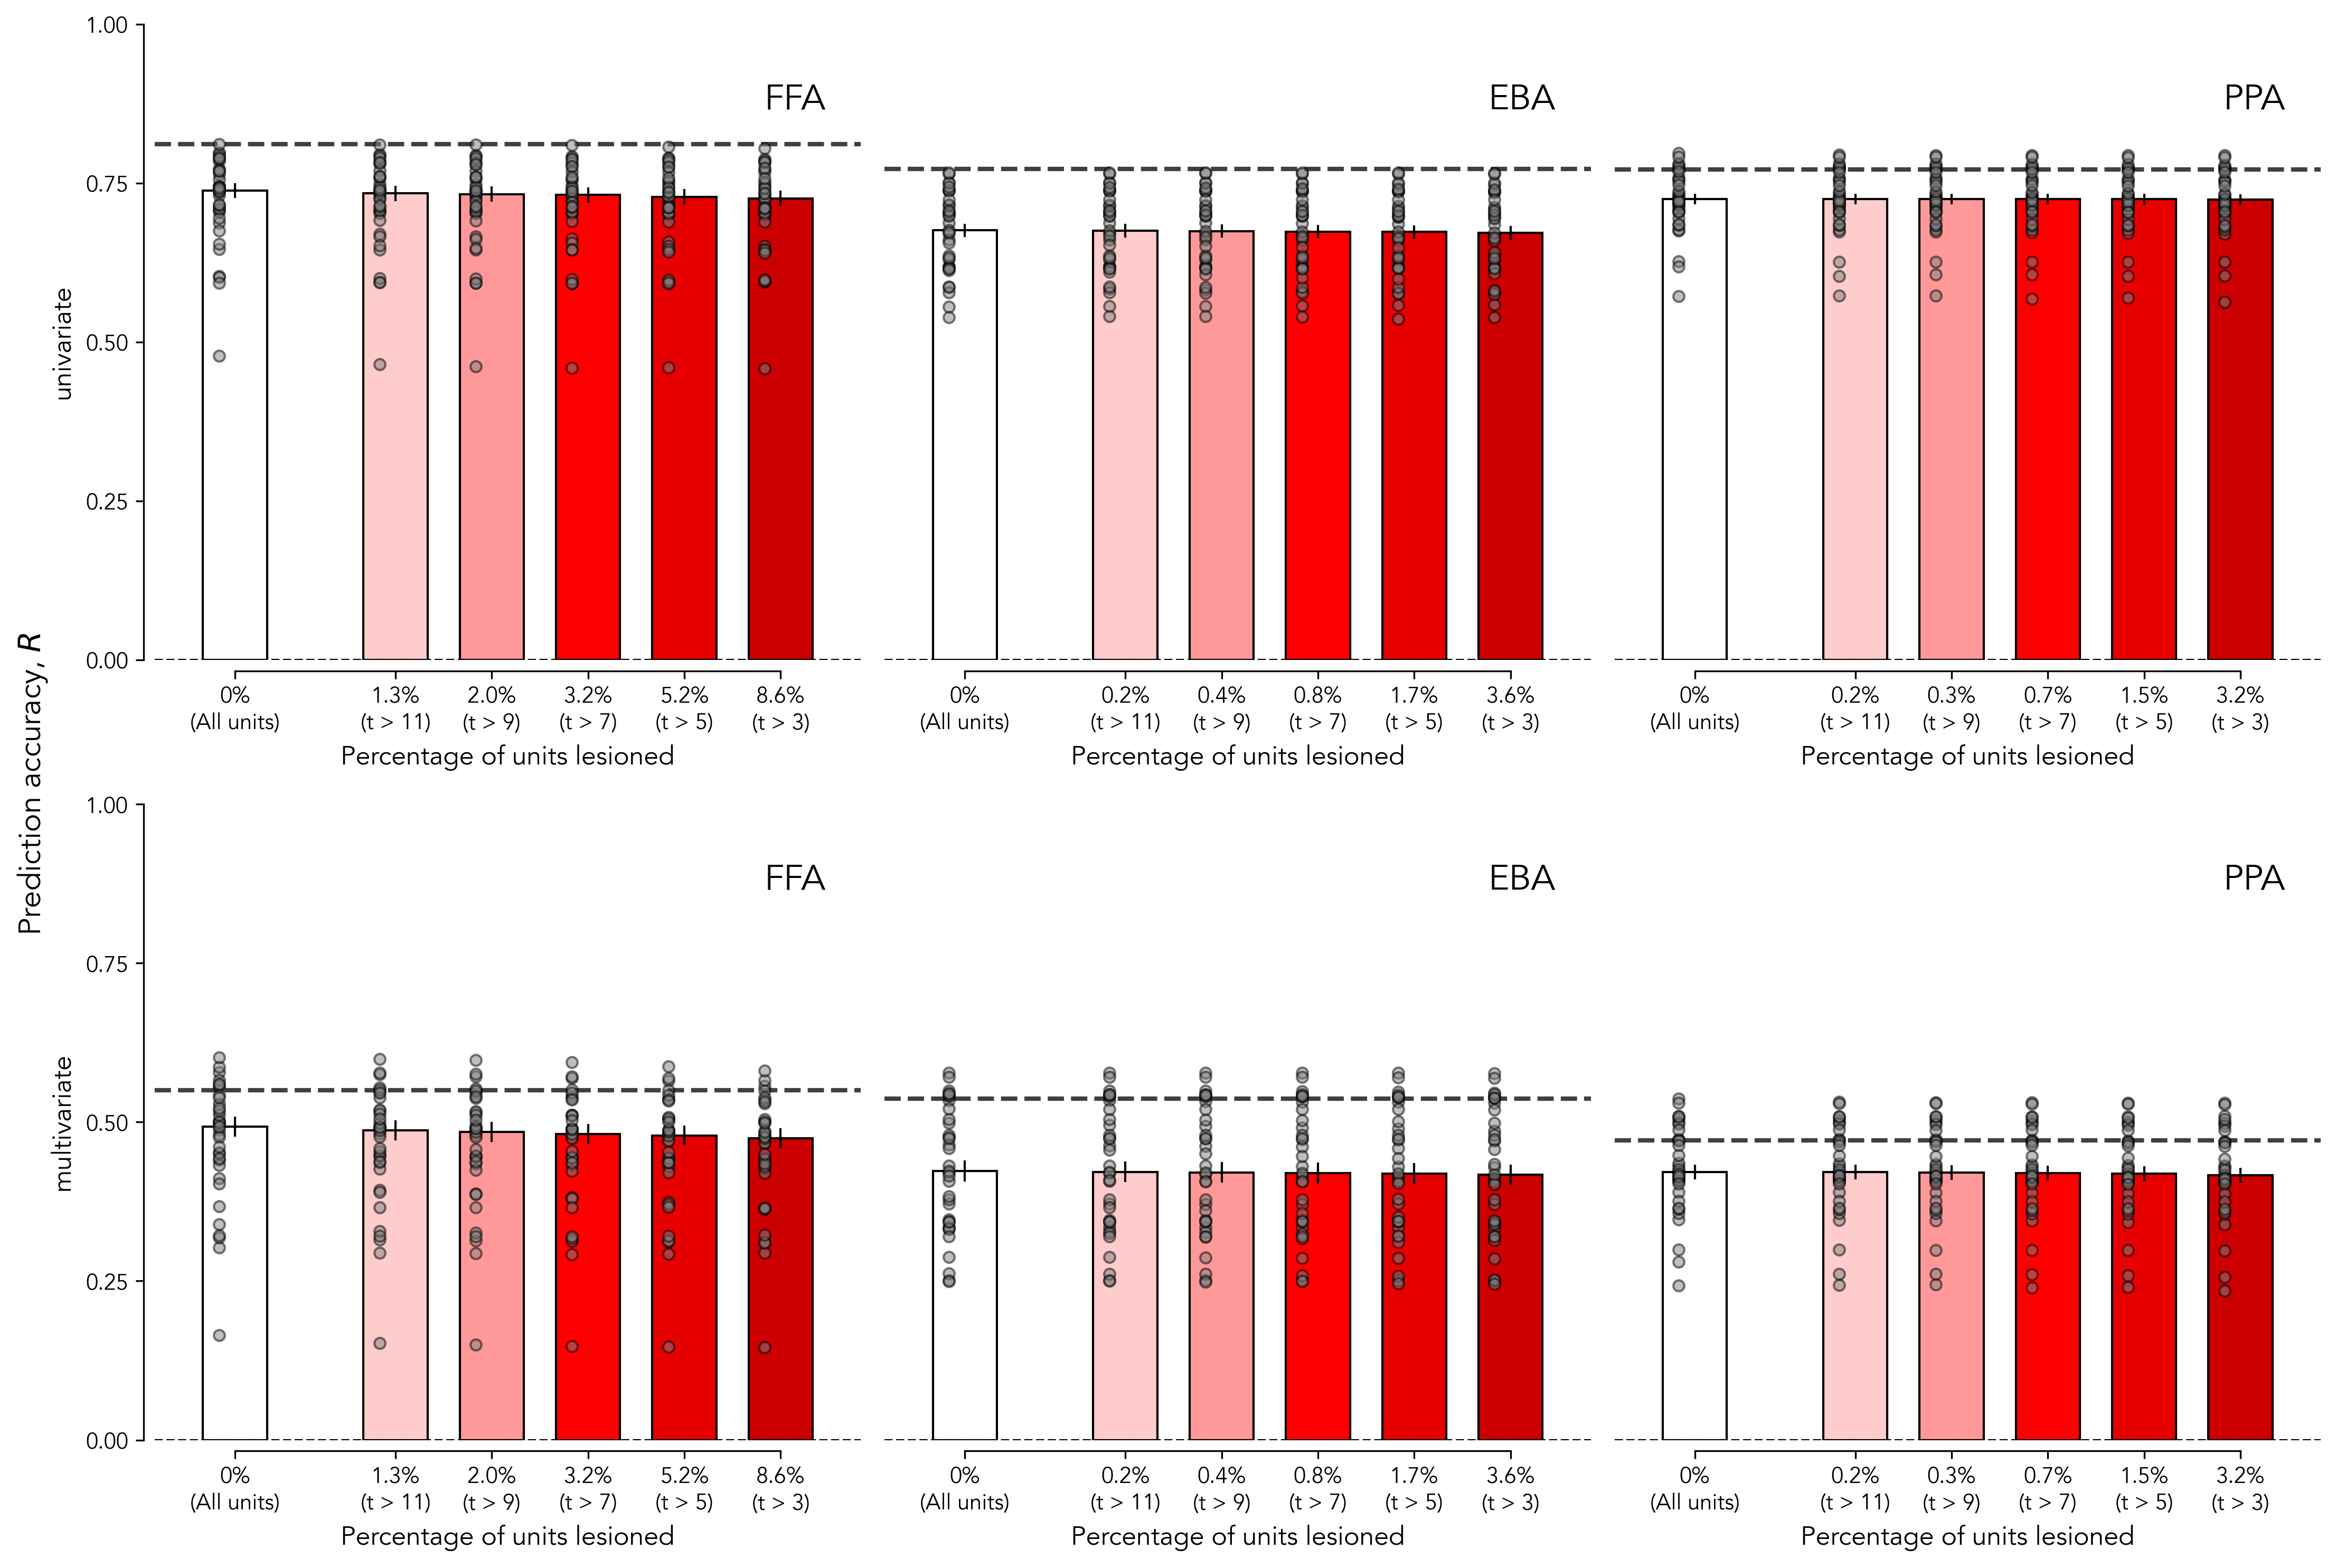

In [13]:
savefig = False

plot_dir = f'{PLOTS_DIR}/supplementary_figures'
os.makedirs(plot_dir, exist_ok=True)

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

fmri_tthreshold = 7

results_df = lesion_csv.copy()
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
subjects = results_df['subject'].unique().tolist()

frois = ['FFA', 'EBA', 'PPA']
ordered_tthresholds = [-1, 11, 9, 7, 5, 3]
xticks_dict = {
    -1: 'Intact',
    11: '11',
    9: '9',
    7: '7',
    5: '5',
    3: '3'
}
metrics = ['raw_pearsonr', 'raw_rdmr']
plot_ceiling = True

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [-0.2, 0.3, 0.6, 0.9, 1.2, 1.5]
fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

colors = [
    '#ffffff',  # white for intact
    '#ffcccc',  # very light red
    '#ff9999',  # light red
    '#ff0000',  # pure red (middle)
    '#e60000',  # slightly darker red
    '#cc0000',  # darker red
]

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        print(metric, froi)
        # For specific froi & fmri_tthreshold, get results_df
        results_df_froi = results_df[
            (results_df['model_froi'] == froi) &
            (results_df['fmri_froi'] == froi) &
            (results_df['fmri_tthreshold'] == fmri_tthreshold)
        ]
        # Take median across subjects for each model, model_threshold
        results_df_froi_sbjmedian = results_df_froi.groupby(
            ['model', 'model_tthreshold']
        ).agg({
            'raw_pearsonr': 'median',
            'normed_pearsonr': 'median',
            'raw_rdmr': 'median',
            'normed_rdmr': 'median',
            'n_units_layer': 'mean',
            'n_units_lesioned': 'mean',
            'percent_units_lesioned': 'mean',
            'fmri_splithalf_pearsonr': 'median',
            'fmri_splithalf_rdmr': 'median',
        }).reset_index()

        if plot_ceiling:
            metric_str = 'fmri_splithalf_' + metric.replace('raw_', '')
            axs[midx, fidx].axhline(
                y=results_df_froi_sbjmedian[metric_str].values[0],
                color='k', linestyle='--', alpha=0.75, linewidth=2
            )
            # ceiling_values = []
            # for subject1_idx in range(len(subjects)):
            #     for subject2_idx in range(subject1_idx, len(subjects)):
            #         subject1 = subjects[subject1_idx]
            #         subject2 = subjects[subject2_idx]
            #         if subject1 == subject2:
            #             continue
            #         subjectsubject_froi = subjectsubject_correlations_csv[
            #             (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            #             (subjectsubject_correlations_csv['subject1'] == subject1) &
            #             (subjectsubject_correlations_csv['subject2'] == subject2) & 
            #             (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
            #         ]
            #         ceiling_metric_ = 'pearsonr' if metric == 'raw_pearsonr' else metric
            #         ceiling_values += list(subjectsubject_froi[ceiling_metric_])
            #         # print(f'Subject {subject1} vs Subject {subject2}: {subjectsubject_froi[ceiling_metric]}')
            # ceiling_values = np.array(ceiling_values).flatten()
            # # print(f'Ceiling values: {ceiling_values}')
            # ceiling_median = np.median(ceiling_values)
            # ceiling_sem = np.std(ceiling_values) / np.sqrt(len(ceiling_values))

            # # Plot horizontal line at median of ceiling values
            # plt.axhline(y=ceiling_median, color='royalblue', linestyle='-', alpha=0.8, linewidth=1, zorder=1)

            # Fill area around the line for SEM
            # plt.fill_between(
            #     [x[0]-0.5, x[1]+0.5],  # Extend across full x range
            #     ceiling_median - ceiling_sem,
            #     ceiling_median + ceiling_sem,
            #     color='royalblue', alpha=0.2, zorder=0, edgecolor='none'
            # )

        
        # model_tthresholds = results_df_froi_sbjmedian['model_tthreshold'].unique()
        model_tthresholds = ordered_tthresholds
        assert set(model_tthresholds) == set(ordered_tthresholds), \
            f"Model tthresholds {model_tthresholds} are same as ordered tthresholds {ordered_tthresholds}"
        n_model_tthresholds = len(model_tthresholds)

        # percent_lesioned_means = []
        # percent_lesioned_sems = []

        xticklabels = []

        for tidx, model_tthreshold in enumerate(model_tthresholds):
            tthreshold_results = results_df_froi_sbjmedian[
                (results_df_froi_sbjmedian['model_tthreshold'] == model_tthreshold)
            ]
            y_pts = tthreshold_results[metric].values
            percent_lesioneds = tthreshold_results['percent_units_lesioned'].values
            pl_mean = np.mean(percent_lesioneds)
            pl_sem = np.std(percent_lesioneds) / np.sqrt(len(percent_lesioneds))
            # percent_lesioned_means.append(np.mean(percent_lesioneds))
            # percent_lesioned_sems.append(np.std(percent_lesioneds) / np.sqrt(len(percent_lesioneds)))
            # Add text on top of each x point mentioning the percent lesioned mean +- sem
            # axs[midx, fidx].text(
            #     x[tidx] + x_offset, 0.95,
            #     f"{pl_mean:.1f} ± {pl_sem:.1f}%",
            #     horizontalalignment='center', verticalalignment='bottom',
            #     fontsize=8, color='black', alpha=0.8
            # )
            # instead of text, make it x tick labels
            if model_tthreshold == -1:
                xticklabels.append('0%\n(All units)')
            else:
                xticklabels.append(f"{pl_mean:.1f}%\n(t > {model_tthreshold})")
        
            x_froi = (np.ones(len(y_pts)) * x[tidx]) - x_offset
            axs[midx, fidx].scatter(
                x_froi, y_pts, color='gray', alpha=alpha, zorder=2,
                edgecolors='k', s=markersize
            )
            # connect points with a line
            # for i in range(len(froi_pts)):
            #     axs[midx, fidx].plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

            # Bar plot with median and SEM
            bar_width = 0.2 #0.4
            median = np.median(y_pts)
            sem = y_pts.std() / np.sqrt(len(y_pts))

            axs[midx, fidx].bar(
                x[tidx], median, yerr=sem, width=bar_width, color=colors[tidx],
                alpha=1, capsize=0, error_kw={'linewidth': 1}, edgecolor='k'
            )
            # # Conduct Welch's t-test
            # t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
            # # axs[midx, fidx].text(0.95, 0.89,
            # #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
            # #          horizontalalignment='right', verticalalignment='bottom',
            # #          transform=axs[midx, fidx].transAxes)
            # print(f"t-value: {t_value:.2f}\np-value: {p_value:.2e}")
        axs[midx, fidx].text(0.95, 0.85,
                    froi,
                    horizontalalignment='right', verticalalignment='bottom',
                    transform=axs[midx, fidx].transAxes, fontsize=16, fontweight='bold')

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        axs[midx, fidx].set_ylim(0, 1)
        # axs[midx, fidx].tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        # xticklabels = [xticks_dict[t] for t in model_tthresholds]
        axs[midx, fidx].set_xticks(x, xticklabels, fontsize=10)
        # axs[midx, fidx].xticks(x, model_tthresholds)
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # axs[midx, fidx].tick_params(axis='x', labelbottom=False)
        axs[midx, fidx].set_xlabel('Percentage of units lesioned', fontsize=12)
        if 'pearsonr' in metric:
            axs[midx, fidx].set_ylabel(f'univariate', fontsize=12)
        elif 'rdmr' in metric:
            axs[midx, fidx].set_ylabel(f'multivariate', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')
        # plt.title(f'{froi} fROI, mapper: Ridge', fontsize=14, pad=10)

fig.supylabel(r"Prediction accuracy, $R$", fontsize=14)
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/figS9_EMlesions_acrosstthresholds.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

## Fig S10: L1-positive mapping

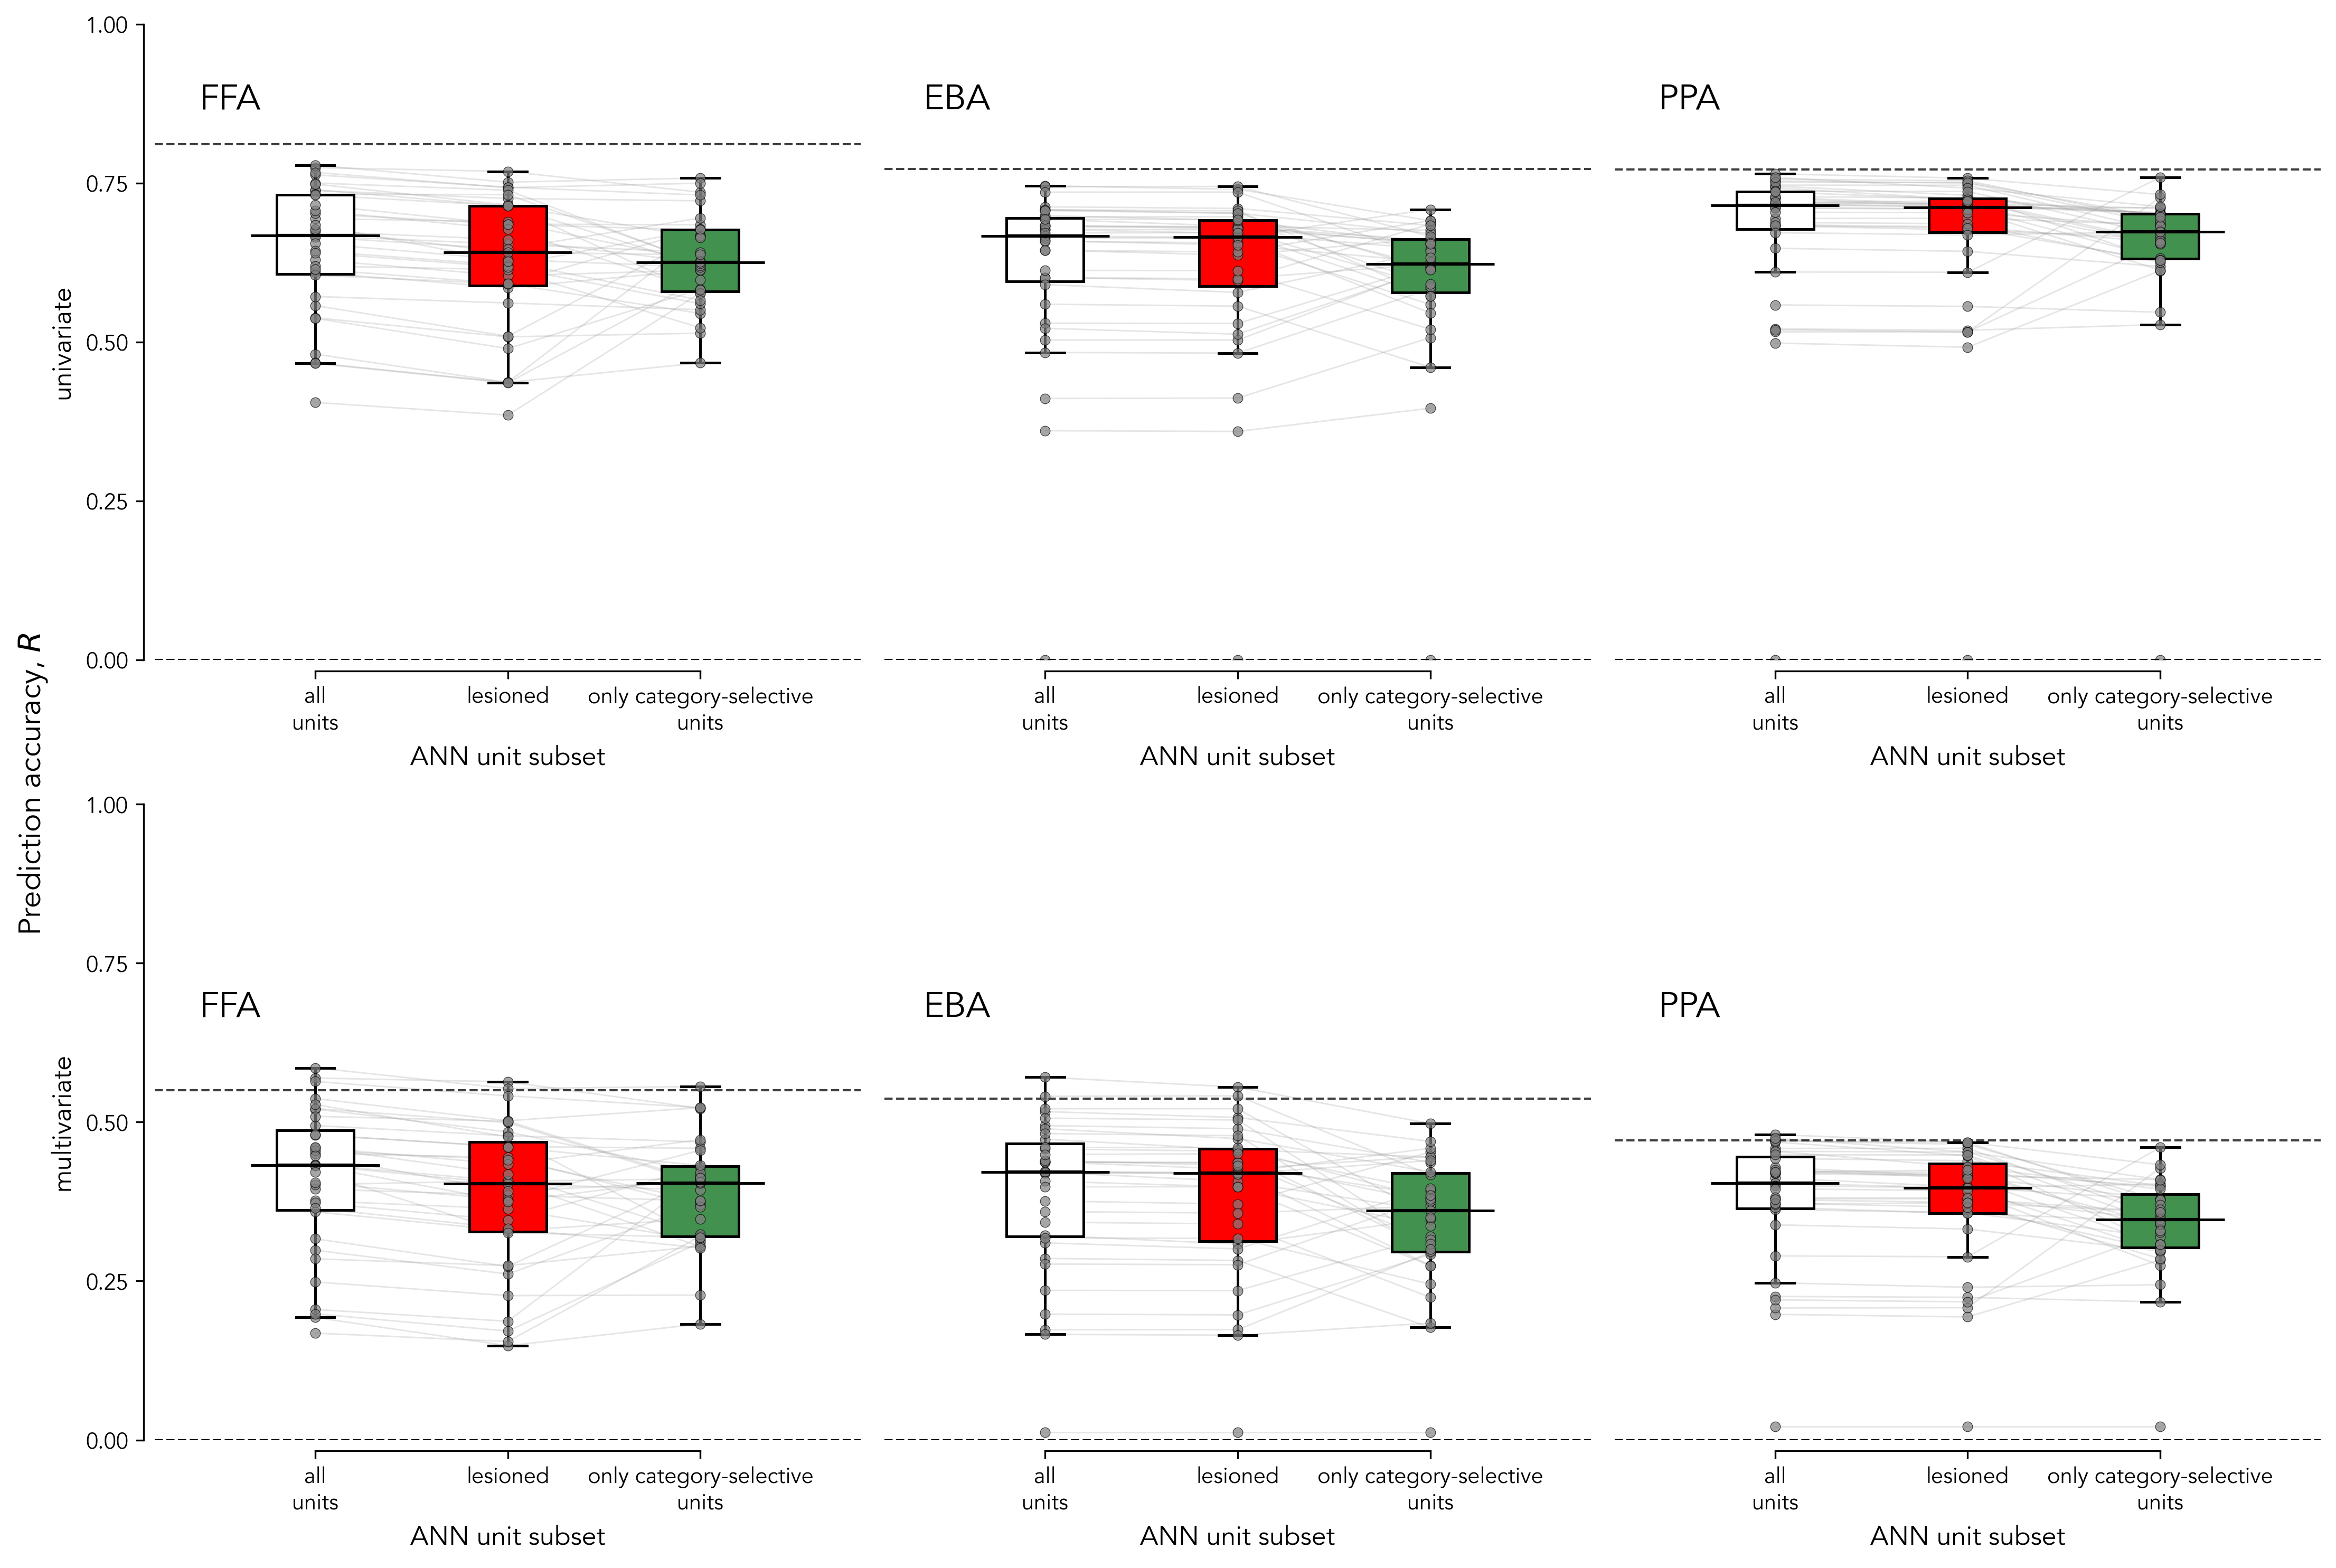

In [34]:
savefig = True

plot_dir = f'{PLOTS_DIR}/supplementary_figures'
os.makedirs(plot_dir, exist_ok=True)

lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

results_df = lesion_csv.copy()
frois = ['FFA', 'EBA', 'PPA']
t_threshold = 7
mapper = 'l1pos'
alpha = 0.01
subjects = [1, 2, 5, 7]
metrics = ['raw_pearsonr', 'raw_rdmr']
layer_lesion_froi_stats_df = []

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold) &
    (results_df['mapper'] == mapper) &
    (results_df['alpha'] == alpha)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
	'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'percent_units_lesioned': 'median',
    'fmri_splithalf_pearsonr': 'median',
    'fmri_splithalf_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(
    len(metrics), len(frois),
    figsize=(5*len(frois), 5*len(metrics)),
    dpi=300
)

# --- style (borrowed from your mimic code + paper figure) ---
x_offset = 0 # 0.05
pt_alpha = 0.7 # 0.6
markersize = 20 # 25
bar_width = 0.12 # 0.20

x = np.array([0.0, 0.3, 0.6])

# paper-like fills
bar_colors = ['#ffffff', '#ff0000', '#43914e']  # white, red, green
pt_color = 'gray'  # like your mimic code

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]

    # ceiling per froi
    ceiling = {
        'raw_pearsonr': results_df_froi['fmri_splithalf_pearsonr'].values[0],
        'raw_rdmr': results_df_froi['fmri_splithalf_rdmr'].values[0],
    }

    for midx, metric in enumerate(metrics):
        ax = axs[midx, fidx]

        # ceiling dashed line (match mimic code)
        ax.axhline(
            y=ceiling[metric],
            color='k', linestyle='--', alpha=0.75, linewidth=1
        )

        # collect points
        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())
        froi_pts  = np.array(results_df_froi[f'froi_{metric}'].tolist())

        # x coords (small shift left)
        x_layer  = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        x_froi   = (np.ones(len(froi_pts))  * x[2]) - x_offset

        # connect triplets (light gray, thin)
        for i in range(len(froi_pts)):
            ax.plot(
                [x_layer[i], x_lesion[i], x_froi[i]],
                [layer_pts[i], lesion_pts[i], froi_pts[i]],
                color='0.6', alpha=0.25, linewidth=0.7, zorder=1
            )

        # If you want open circles instead (closer to the screenshot),
        # replace the three scatters above with facecolors='none' and set alpha=1.

        # bars: median ± SEM (paper style)
        pts_list = [layer_pts, lesion_pts, froi_pts]
        medians = [np.median(p) for p in pts_list]
        # sems = [np.std(p, ddof=1) / np.sqrt(len(p)) for p in pts_list]

        # ax.bar(
        #     x, medians,
        #     yerr=sems,
        #     width=bar_width,
        #     color=bar_colors,
        #     alpha=1,
        #     capsize=0,
        #     edgecolor='k',
        #     linewidth=1.0,
        #     error_kw={'linewidth': 1.0, 'ecolor': 'k'},
        #     zorder=0
        # )

        box = ax.boxplot(
            pts_list,
            positions=x,
            widths=bar_width,
            patch_artist=True,
            showfliers=False,
            medianprops=dict(color='k', linewidth=1.5),
            boxprops=dict(linewidth=1.2, edgecolor='k'),
            whiskerprops=dict(linewidth=1.2, color='k'),
            capprops=dict(linewidth=1.2, color='k'),
        )

        # color the boxes
        for patch, color in zip(box['boxes'], bar_colors):
            patch.set_facecolor(color)
        
        for i, data in enumerate(box['medians']):
            med = medians[i]
            # Manually draw a longer median line
            x_ = x[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x_ - 0.1, x_ + 0.1], [med, med], color='black', linewidth=1.2, solid_capstyle='butt')
        
        # scatter points (inspired by your mimic)
        # Option A (closer to mimic): gray filled w/ black edge
        ax.scatter(x_layer,  layer_pts,  color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.3)
        ax.scatter(x_lesion, lesion_pts, color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.3)
        ax.scatter(x_froi,   froi_pts,   color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.3)

        # % lesioned text (keep your original behavior)
        # percent_lesioned_list = results_df_froi['percent_units_lesioned'].values
        # pl_mean = np.mean(percent_lesioned_list)
        # pl_sem = np.std(percent_lesioned_list, ddof=1) / np.sqrt(len(percent_lesioned_list))
        # ax.text(
        #     x[-1], 0.95,
        #     f"{pl_mean:.1f} ± {pl_sem:.1f}%",
        #     ha='center', va='bottom',
        #     fontsize=11, color='black', alpha=0.85
        # )

        # fROI label (bold, like your mimic)
        if metric == 'raw_pearsonr':
            ax.text(
                0.15, 0.85, froi,
                ha='right', va='bottom',
                transform=ax.transAxes,
                fontsize=16, fontweight='bold'
            )
        else:
            ax.text(
                0.15, 0.65, froi,
                ha='right', va='bottom',
                transform=ax.transAxes,
                fontsize=16, fontweight='bold'
            )

        # baseline at 0
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        # cosmetic spines/ticks (match mimic)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))

        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
        ax.spines['left'].set_bounds(0, 1)
        ax.spines['bottom'].set_bounds(x[0], x[-1])
        ax.set_xlim(x[0]-0.25, x[-1]+0.25)

        ax.set_xticks(x, ['all\nunits', 'lesioned', 'only category-selective\nunits'], fontsize=10)

        # optional: add "lesioned" bracket-ish label under first two bars (paper-like)
        # ax.text(
        #     (x[0]+x[1])/2, -0.18, "lesioned",
        #     ha='center', va='top',
        #     transform=ax.get_xaxis_transform(),
        #     fontsize=11
        # )

        # labels: only leftmost y, only bottom x
        if fidx == 0:
            if 'pearsonr' in metric:
                ax.set_ylabel('univariate', fontsize=12)
            else:
                ax.set_ylabel('multivariate', fontsize=12)
        else:
            ax.spines['left'].set_visible(False)
            ax.yaxis.set_ticks([])
            ax.set_ylabel('')

        # if midx == len(metrics) - 1:
        ax.set_xlabel('ANN unit subset', fontsize=12)
        # else:
        #     ax.set_xlabel('')

fig.supylabel(r"Prediction accuracy, $R$", fontsize=14)
plt.tight_layout()

if savefig:
    plt.savefig(
        f'{plot_dir}/figS10_lesioining_L1positive.pdf',
        dpi=300, bbox_inches='tight', transparent=True
    )
plt.show()
plt.close()

### Legacy: Bar plots

In [22]:
savefig = True

plot_dir = f'{PLOTS_DIR}/supplementary_figures'
os.makedirs(plot_dir, exist_ok=True)

fig, axs = plt.subplots(
    len(metrics), len(frois),
    figsize=(5*len(frois), 5*len(metrics)),
    dpi=300
)

# --- style (borrowed from your mimic code + paper figure) ---
x_offset = 0.05
pt_alpha = 0.6
markersize = 25
bar_width = 0.20

x = np.array([0.0, 0.3, 0.6])

# paper-like fills
bar_colors = ['#ffffff', '#ff0000', '#43914e']  # white, red, green
pt_color = 'gray'  # like your mimic code

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]

    # ceiling per froi
    ceiling = {
        'raw_pearsonr': results_df_froi['fmri_splithalf_pearsonr'].values[0],
        'raw_rdmr': results_df_froi['fmri_splithalf_rdmr'].values[0],
    }

    for midx, metric in enumerate(metrics):
        ax = axs[midx, fidx]

        # ceiling dashed line (match mimic code)
        ax.axhline(
            y=ceiling[metric],
            color='k', linestyle='--', alpha=0.75, linewidth=2
        )

        # collect points
        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())
        froi_pts  = np.array(results_df_froi[f'froi_{metric}'].tolist())

        # x coords (small shift left)
        x_layer  = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        x_froi   = (np.ones(len(froi_pts))  * x[2]) - x_offset

        # connect triplets (light gray, thin)
        for i in range(len(froi_pts)):
            ax.plot(
                [x_layer[i], x_lesion[i], x_froi[i]],
                [layer_pts[i], lesion_pts[i], froi_pts[i]],
                color='0.6', alpha=0.25, linewidth=0.7, zorder=1
            )

        # scatter points (inspired by your mimic)
        # Option A (closer to mimic): gray filled w/ black edge
        ax.scatter(x_layer,  layer_pts,  color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.7)
        ax.scatter(x_lesion, lesion_pts, color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.7)
        ax.scatter(x_froi,   froi_pts,   color=pt_color, alpha=pt_alpha, zorder=2,
                   edgecolors='k', s=markersize, linewidths=0.7)

        # If you want open circles instead (closer to the screenshot),
        # replace the three scatters above with facecolors='none' and set alpha=1.

        # bars: median ± SEM (paper style)
        pts_list = [layer_pts, lesion_pts, froi_pts]
        medians = [np.median(p) for p in pts_list]
        sems = [np.std(p, ddof=1) / np.sqrt(len(p)) for p in pts_list]

        ax.bar(
            x, medians,
            yerr=sems,
            width=bar_width,
            color=bar_colors,
            alpha=1,
            capsize=0,
            edgecolor='k',
            linewidth=1.0,
            error_kw={'linewidth': 1.0, 'ecolor': 'k'},
            zorder=0
        )

        # % lesioned text (keep your original behavior)
        # percent_lesioned_list = results_df_froi['percent_units_lesioned'].values
        # pl_mean = np.mean(percent_lesioned_list)
        # pl_sem = np.std(percent_lesioned_list, ddof=1) / np.sqrt(len(percent_lesioned_list))
        # ax.text(
        #     x[-1], 0.95,
        #     f"{pl_mean:.1f} ± {pl_sem:.1f}%",
        #     ha='center', va='bottom',
        #     fontsize=11, color='black', alpha=0.85
        # )

        # fROI label (bold, like your mimic)
        if metric == 'raw_pearsonr':
            ax.text(
                0.15, 0.85, froi,
                ha='right', va='bottom',
                transform=ax.transAxes,
                fontsize=16, fontweight='bold'
            )
        else:
            ax.text(
                0.15, 0.65, froi,
                ha='right', va='bottom',
                transform=ax.transAxes,
                fontsize=16, fontweight='bold'
            )

        # baseline at 0
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        # cosmetic spines/ticks (match mimic)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))

        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
        ax.spines['left'].set_bounds(0, 1)
        ax.spines['bottom'].set_bounds(x[0], x[-1])
        ax.set_xlim(x[0]-0.25, x[-1]+0.25)

        ax.set_xticks(x, ['all\nunits', 'lesioned', 'only category-selective\nunits'], fontsize=10)

        # optional: add "lesioned" bracket-ish label under first two bars (paper-like)
        # ax.text(
        #     (x[0]+x[1])/2, -0.18, "lesioned",
        #     ha='center', va='top',
        #     transform=ax.get_xaxis_transform(),
        #     fontsize=11
        # )

        # labels: only leftmost y, only bottom x
        if fidx == 0:
            if 'pearsonr' in metric:
                ax.set_ylabel('univariate', fontsize=12)
            else:
                ax.set_ylabel('multivariate', fontsize=12)
        else:
            ax.spines['left'].set_visible(False)
            ax.yaxis.set_ticks([])
            ax.set_ylabel('')

        # if midx == len(metrics) - 1:
        ax.set_xlabel('ANN unit subset', fontsize=12)
        # else:
        #     ax.set_xlabel('')

fig.supylabel(r"Prediction accuracy, $R$", fontsize=14)
plt.tight_layout()

if savefig:
    plt.savefig(
        f'{plot_dir}/figS10_lesioining_L1positive.pdf',
        dpi=300, bbox_inches='tight', transparent=True
    )
else:
    plt.show()
plt.close()

### Legacy: old colors

In [ ]:
savefig = False

lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

plot_dir = f'{PLOTS_DIR}/supplementary_figures'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
frois = ['FFA', 'EBA', 'PPA']
t_threshold = 7
mapper = 'l1pos'
alpha = 0.01
subjects = [1, 2, 5, 7]
metrics = ['raw_pearsonr', 'raw_rdmr']
layer_lesion_froi_stats_df = []

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold) &
    (results_df['mapper'] == mapper) &
    (results_df['alpha'] == alpha)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
	'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'percent_units_lesioned': 'median',
    'fmri_splithalf_pearsonr': 'median',
    'fmri_splithalf_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    # Get fmri_splithalf_pearsonr, fmri_splithalf_rdmr from the first row
    ceiling = {
        'raw_pearsonr': results_df_froi['fmri_splithalf_pearsonr'].values[0],
        'raw_rdmr': results_df_froi['fmri_splithalf_rdmr'].values[0],
    }
    for midx, metric in enumerate(metrics):
        # Plot ceiling as a horizontal line
        axs[midx, fidx].axhline(y=ceiling[metric], color='k', linestyle='--', alpha=0.75, linewidth=2)

        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        froi_pts = np.array(results_df_froi[f'froi_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())

        x_layer = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        x_froi = (np.ones(len(froi_pts)) * x[2]) - x_offset
        axs[midx, fidx].scatter(
            x_layer, layer_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(froi_pts)):
            axs[midx, fidx].plot(
                [x_layer[i], x_lesion[i], x_froi[i]], 
                [layer_pts[i], lesion_pts[i], froi_pts[i]], 
                color='red', alpha=0.2, linewidth=0.5, zorder=1
            )

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(layer_pts), np.median(lesion_pts), np.median(froi_pts)]
        sems = [
            layer_pts.std() / np.sqrt(len(layer_pts)),
            lesion_pts.std() / np.sqrt(len(lesion_pts)),
            froi_pts.std() / np.sqrt(len(froi_pts)),
        ]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})

        # Get % units lesioned for this froi
        percent_lesioned_list = results_df_froi['percent_units_lesioned']
        pl_mean = np.mean(percent_lesioned_list)
        pl_sem = percent_lesioned_list.std() / np.sqrt(len(percent_lesioned_list))
        axs[midx, fidx].text(
                x[-1], 0.95,
                f"{pl_mean:.1f} ± {pl_sem:.1f}%",
                horizontalalignment='center', verticalalignment='bottom',
                fontsize=12, color='black', alpha=0.8
            )

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        axs[midx, fidx].set_xticks(x, ['All units', 'All units except fROI', 'only fROI units'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'{metric.split("_")[-1]} (median ± SEM)', fontsize=12)
        axs[midx, fidx].set_xlabel(f'Encoding model training features', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/figS10_lesioining_L1positive.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

### Dev

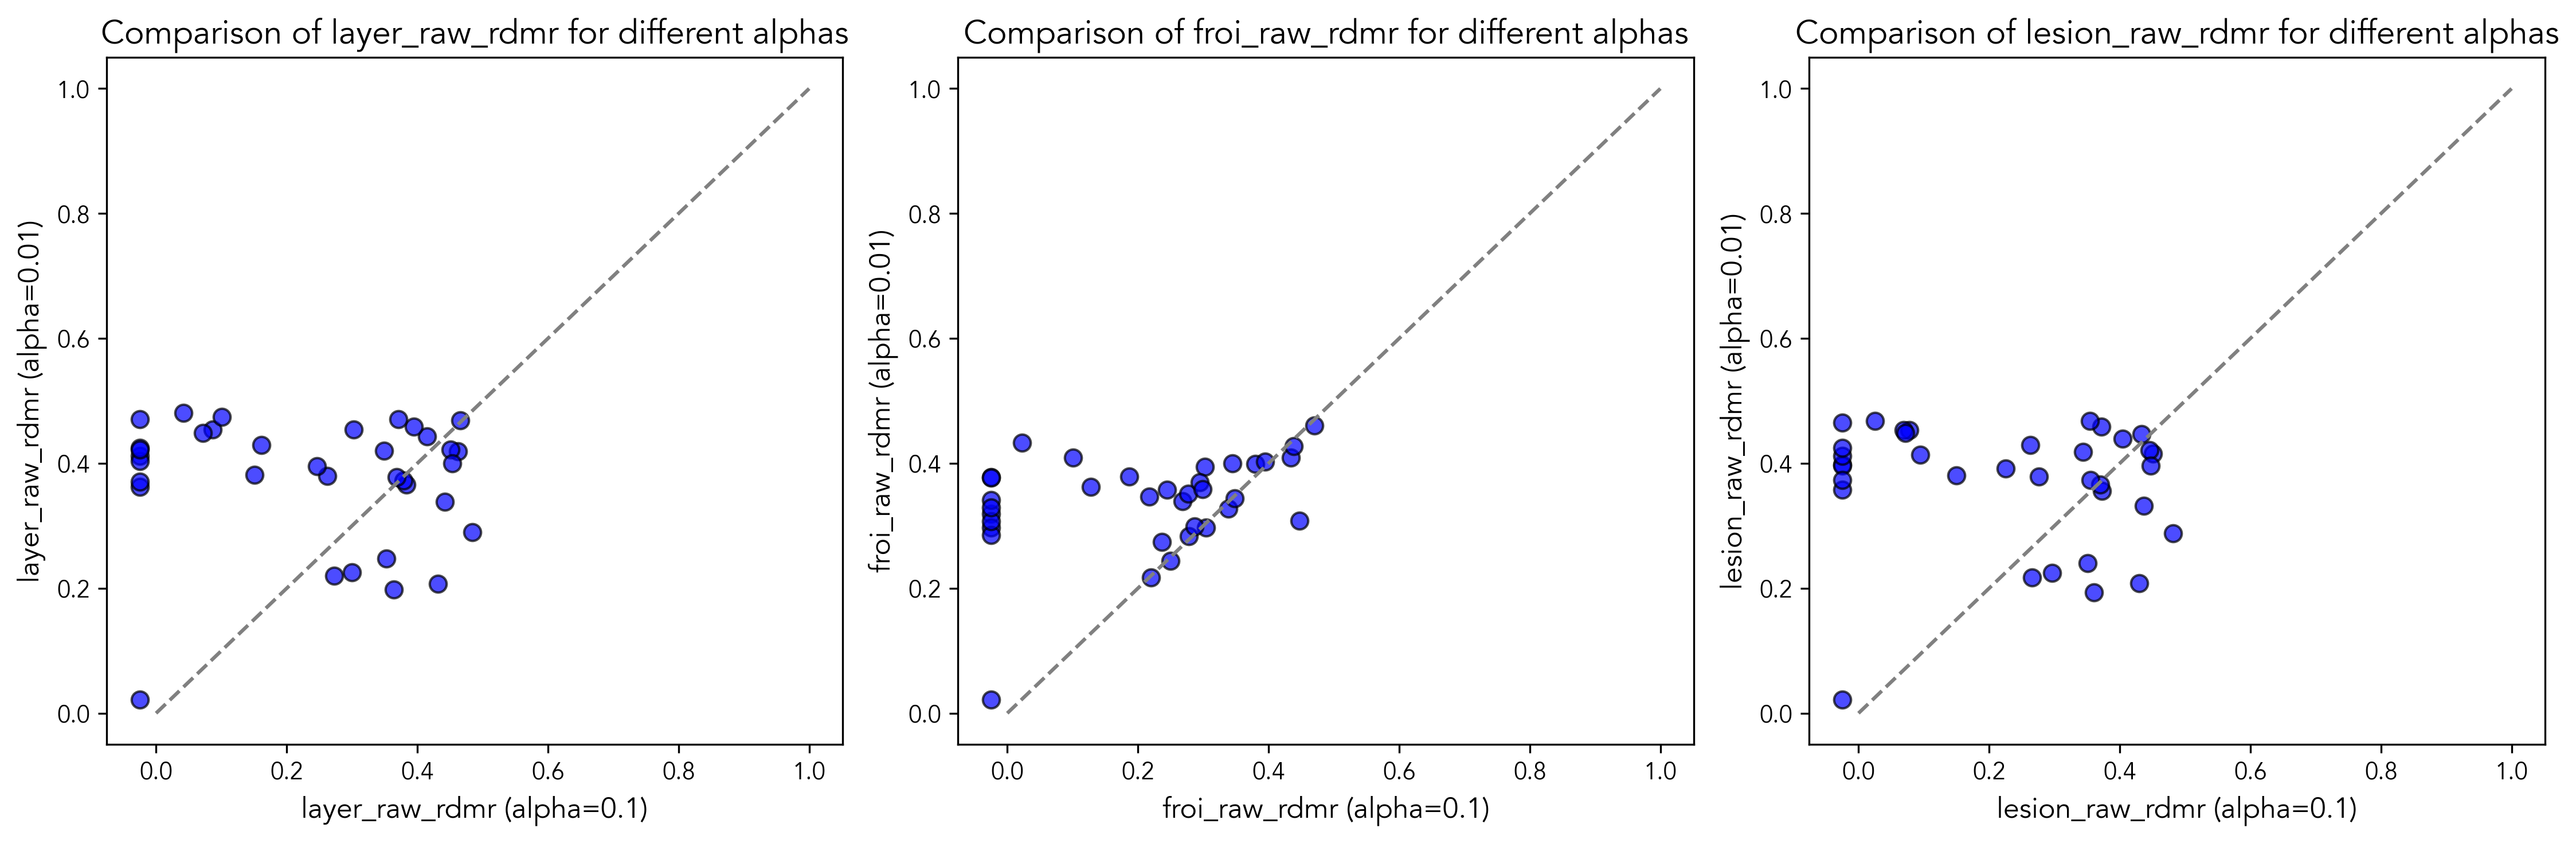

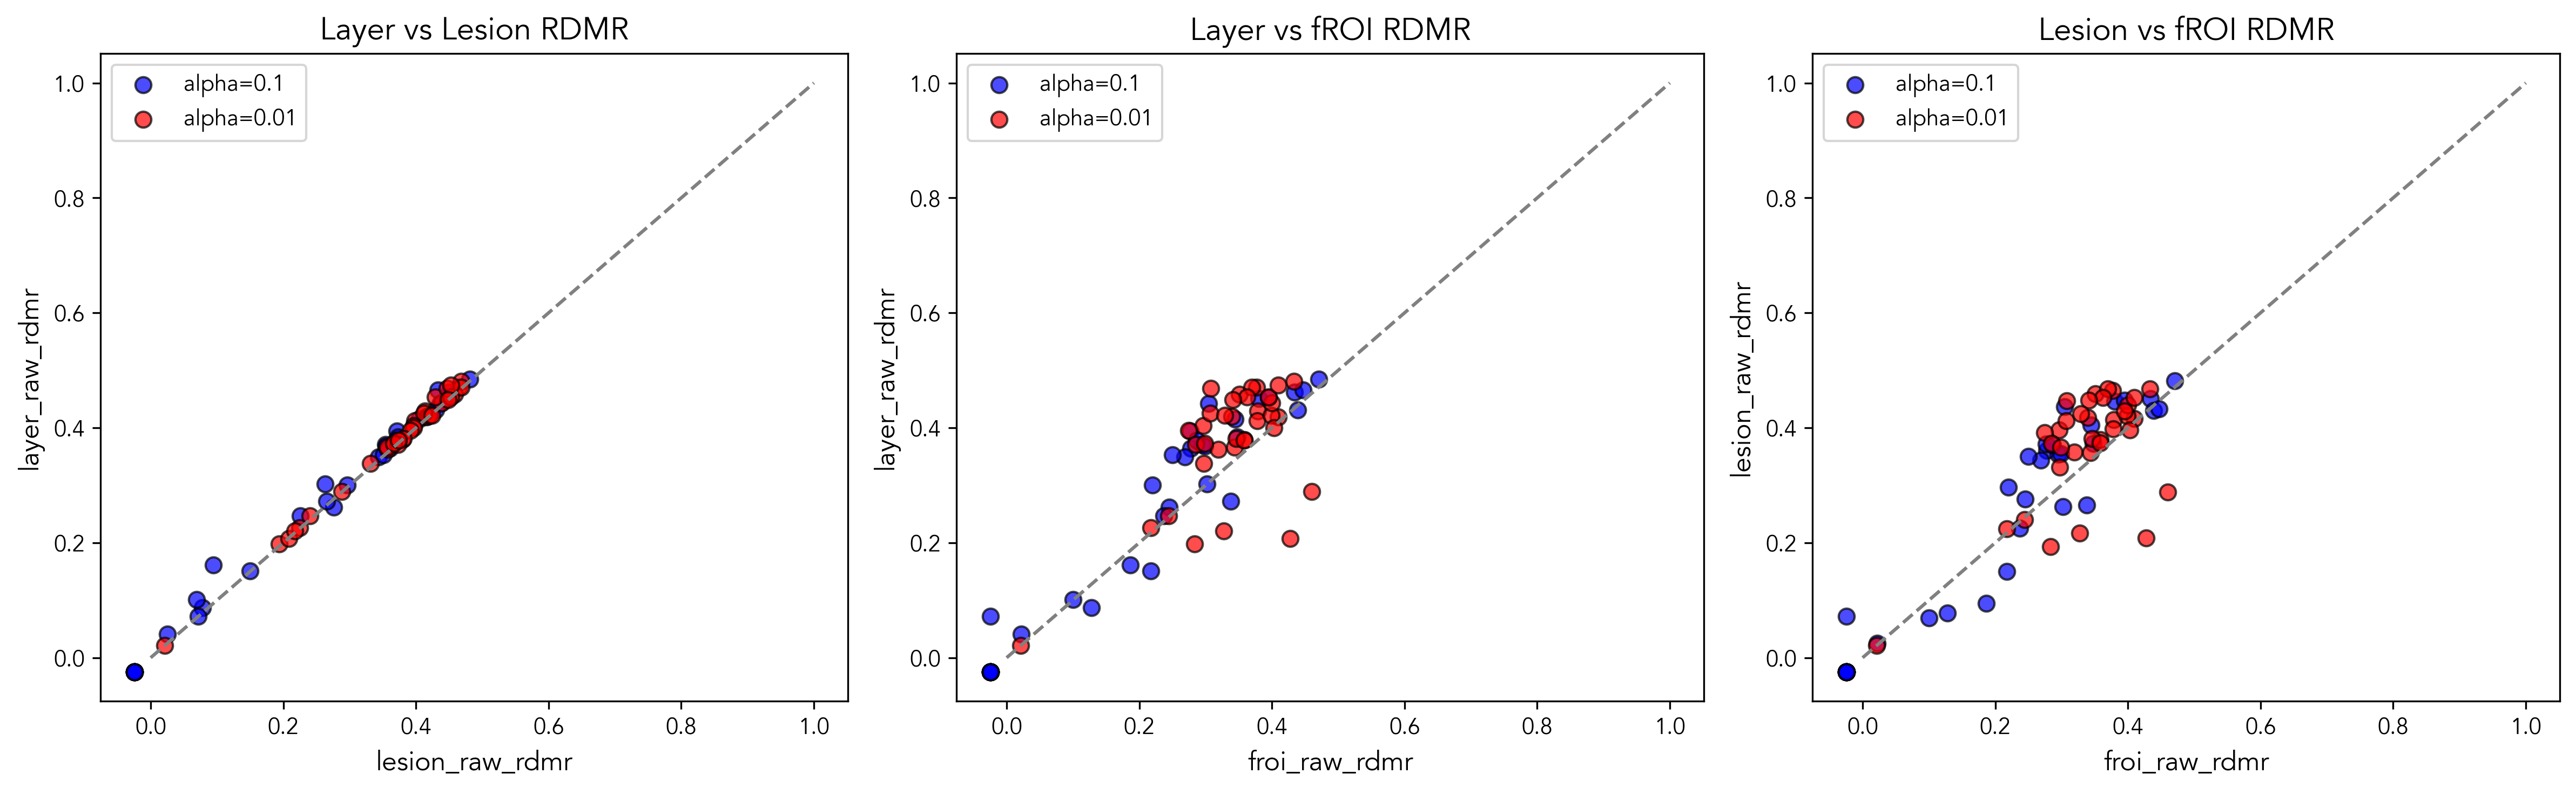

In [20]:
df = lesion_csv[(lesion_csv['mapper'] == 'l1pos') & (lesion_csv['fmri_froi'] == 'PPA')] # & (lesion_csv['alpha'] == 0.01) 

# Get rows that have same model, frois, subject for both alpha 0.1 and 0.01
df_01 = df[df['alpha'] == 0.1]
df_001 = df[df['alpha'] == 0.01]
merged_df = pd.merge(
    df_01, df_001,
    on=['model', 'model_tthreshold', 'model_froi', 'fmri_froi', 'fmri_tthreshold', 'subject'],
    suffixes=('_01', '_001')
)

# results_df_froi_sbjmedian = results_df.groupby(
#     ['model', 'fmri_froi']
# ).agg({
#     'layer_raw_pearsonr': 'median',
#     'layer_raw_rdmr': 'median',
# 	'froi_raw_pearsonr': 'median',
#     'froi_raw_rdmr': 'median',
#     'lesion_raw_pearsonr': 'median',
#     'lesion_raw_rdmr': 'median',
#     'percent_units_lesioned': 'median',
#     'fmri_splithalf_pearsonr': 'median',
#     'fmri_splithalf_rdmr': 'median',
# }).reset_index()

# Aggregate merged_df to get median across subjects for each model, fmri_froi, and alpha
merged_df_agg = merged_df.groupby(
    ['model', 'fmri_froi', 'alpha_01', 'alpha_001']
).agg({
    'layer_raw_pearsonr_01': 'median',
    'layer_raw_rdmr_01': 'median',
    'froi_raw_pearsonr_01': 'median',
    'froi_raw_rdmr_01': 'median',
    'lesion_raw_pearsonr_01': 'median',
    'lesion_raw_rdmr_01': 'median',
    'percent_units_lesioned_01': 'median',
    'fmri_splithalf_pearsonr_01': 'median',
    'fmri_splithalf_rdmr_01': 'median',
    # Repeat for alpha 0.01
    'layer_raw_pearsonr_001': 'median',
    'layer_raw_rdmr_001': 'median',
    'froi_raw_pearsonr_001': 'median',
    'froi_raw_rdmr_001': 'median',
    'lesion_raw_pearsonr_001': 'median',
    'lesion_raw_rdmr_001': 'median',
    'percent_units_lesioned_001': 'median',
    'fmri_splithalf_pearsonr_001': 'median',
    'fmri_splithalf_rdmr_001': 'median',
}).reset_index()

# Make 3 scatter plots comparing alpha 0.1 and 0.01 for layer, froi, and lesion metrics
# first with layer_raw_rdmr (x-axis: alpha 0.1, y-axis: alpha 0.01), then froi_raw_rdmr, then lesion_raw_rdmr
fig, axs = plt.subplots(1, 3, figsize=(15, 5), dpi=300)
metrics = ['layer_raw_rdmr', 'froi_raw_rdmr', 'lesion_raw_rdmr']
savefig = False
for i, metric in enumerate(metrics):
    x_metric = metric + '_01'
    y_metric = metric + '_001'
    axs[i].scatter(
        merged_df_agg[x_metric], merged_df_agg[y_metric],
        color='blue', alpha=0.7, edgecolors='k', s=50
    )
    # Add a diagonal line for reference
    axs[i].plot([0, 1], [0, 1], color='gray', linestyle='--')
    axs[i].set_xlabel(f'{metric} (alpha=0.1)', fontsize=12)
    axs[i].set_ylabel(f'{metric} (alpha=0.01)', fontsize=12)
    axs[i].set_title(f'Comparison of {metric} for different alphas', fontsize=14)
plt.tight_layout()
plt.show()
plt.close()

# Make 2 scatter plots comparing lesion vs layer and froi vs layer for different alphas
fig, axs = plt.subplots(1, 3, figsize=(16, 5), dpi=300)

# Plot 1: lesion_raw_rdmr (x-axis) vs layer_raw_rdmr (y-axis)
axs[0].scatter(
    merged_df_agg['lesion_raw_rdmr_01'], merged_df_agg['layer_raw_rdmr_01'],
    color='blue', alpha=0.7, edgecolors='k', s=50, label='alpha=0.1'
)
axs[0].scatter(
    merged_df_agg['lesion_raw_rdmr_001'], merged_df_agg['layer_raw_rdmr_001'],
    color='red', alpha=0.7, edgecolors='k', s=50, label='alpha=0.01'
)
# Add a diagonal line for reference
axs[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axs[0].set_xlabel('lesion_raw_rdmr', fontsize=12)
axs[0].set_ylabel('layer_raw_rdmr', fontsize=12)
axs[0].set_title('Layer vs Lesion RDMR', fontsize=14)
axs[0].legend()

# Plot 2: froi_raw_rdmr (x-axis) vs layer_raw_rdmr (y-axis)
axs[1].scatter(
    merged_df_agg['froi_raw_rdmr_01'], merged_df_agg['layer_raw_rdmr_01'],
    color='blue', alpha=0.7, edgecolors='k', s=50, label='alpha=0.1'
)
axs[1].scatter(
    merged_df_agg['froi_raw_rdmr_001'], merged_df_agg['layer_raw_rdmr_001'],
    color='red', alpha=0.7, edgecolors='k', s=50, label='alpha=0.01'
)
# Add a diagonal line for reference
axs[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axs[1].set_xlabel('froi_raw_rdmr', fontsize=12)
axs[1].set_ylabel('layer_raw_rdmr', fontsize=12)
axs[1].set_title('Layer vs fROI RDMR', fontsize=14)
axs[1].legend()

# Plot 3: froi_raw_rdmr (x-axis) vs lesion_raw_rdmr (y-axis)
axs[2].scatter(
    merged_df_agg['froi_raw_rdmr_01'], merged_df_agg['lesion_raw_rdmr_01'],
    color='blue', alpha=0.7, edgecolors='k', s=50, label='alpha=0.1'
)
axs[2].scatter(
    merged_df_agg['froi_raw_rdmr_001'], merged_df_agg['lesion_raw_rdmr_001'],
    color='red', alpha=0.7, edgecolors='k', s=50, label='alpha=0.01'
)
# Add a diagonal line for reference
axs[2].plot([0, 1], [0, 1], color='gray', linestyle='--')
axs[2].set_xlabel('froi_raw_rdmr', fontsize=12)
axs[2].set_ylabel('lesion_raw_rdmr', fontsize=12)
axs[2].set_title('Lesion vs fROI RDMR', fontsize=14)
axs[2].legend()

plt.tight_layout()
plt.show()
plt.close()

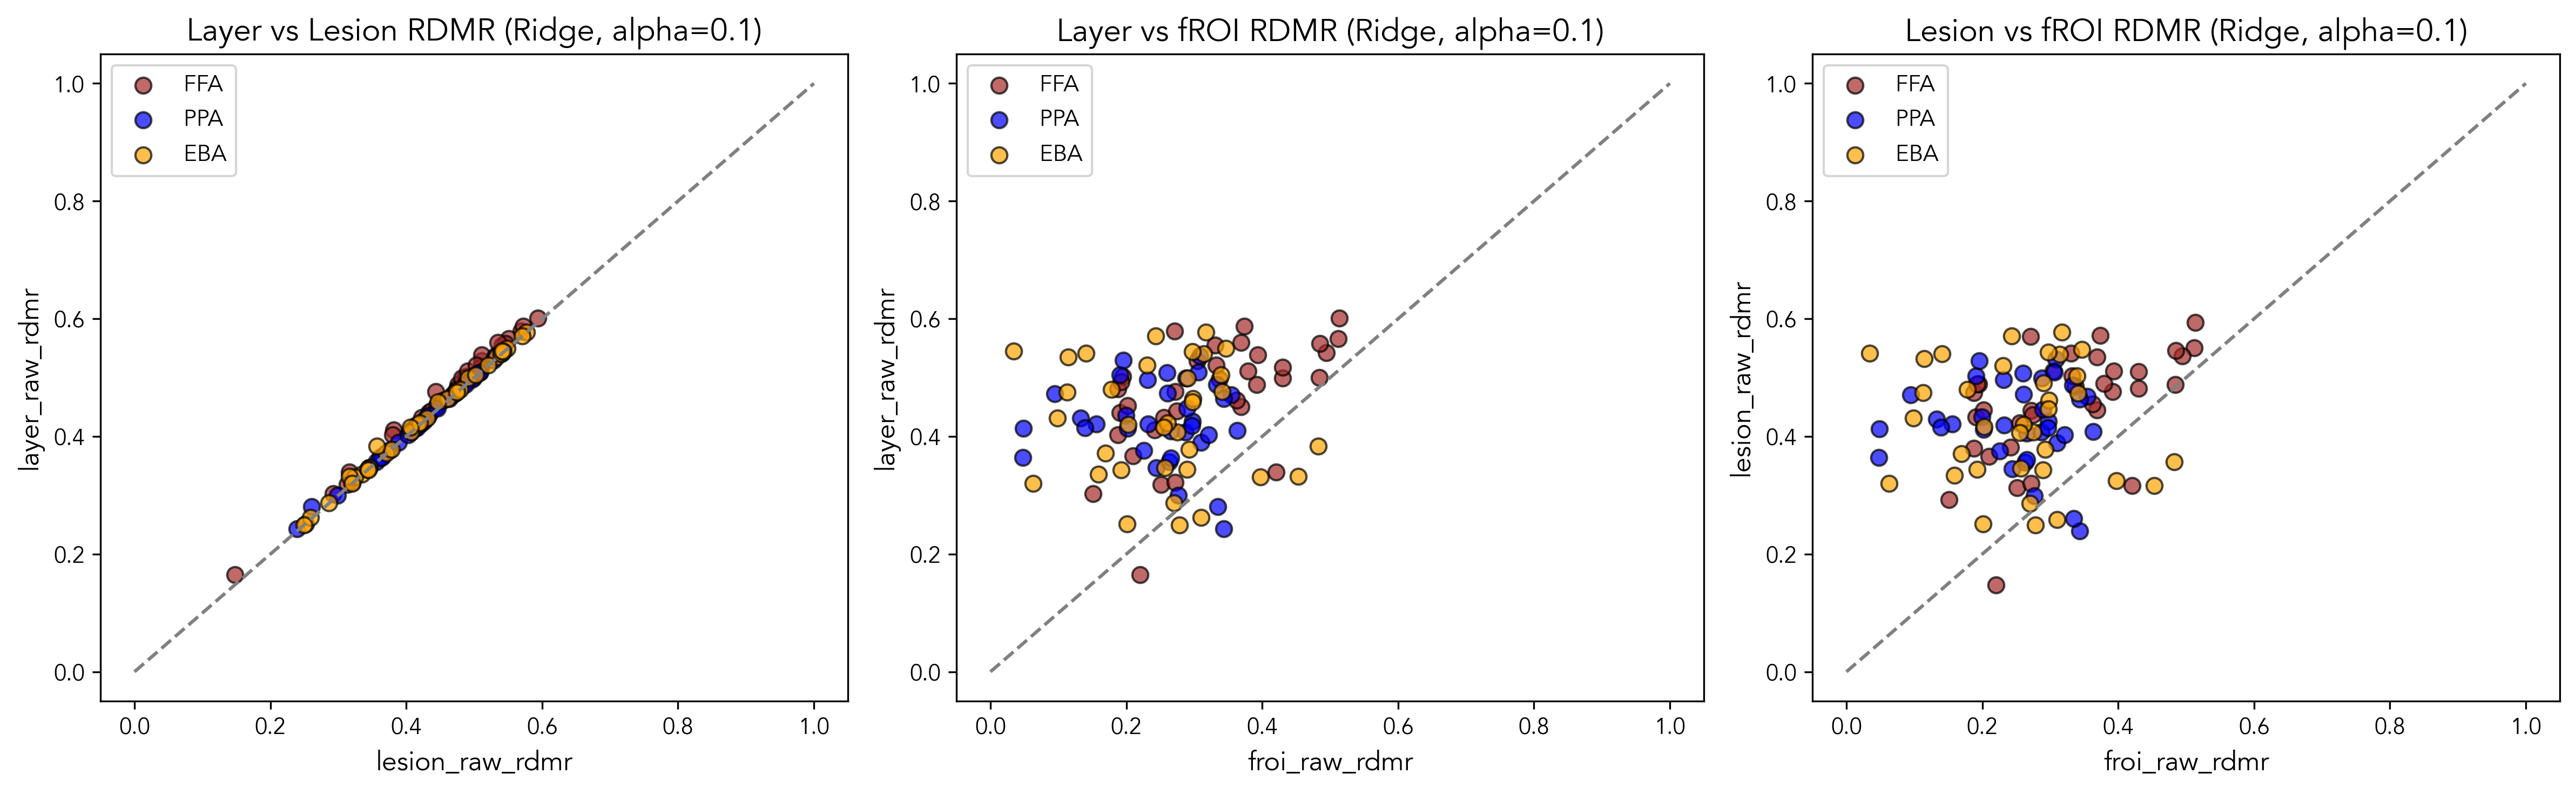

In [23]:
# Filter for ridge mapper and alpha 0.1
df_ridge = lesion_csv[(lesion_csv['mapper'] == 'ridge') & (lesion_csv['alpha'] == 0.1)]

# Aggregate by model and fmri_froi (median across subjects)
df_ridge_agg = df_ridge.groupby(['model', 'fmri_froi']).agg({
    'layer_raw_rdmr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_rdmr': 'median',
}).reset_index()

# Define colors for each fROI
froi_colors = {'FFA': 'brown', 'PPA': 'blue', 'EBA': 'orange'}

# Make 3 scatter plots
fig, axs = plt.subplots(1, 3, figsize=(16, 5), dpi=300)

# Plot 1: lesion_raw_rdmr (x-axis) vs layer_raw_rdmr (y-axis)
for froi in ['FFA', 'PPA', 'EBA']:
    df_froi = df_ridge_agg[df_ridge_agg['fmri_froi'] == froi]
    axs[0].scatter(
        df_froi['lesion_raw_rdmr'], df_froi['layer_raw_rdmr'],
        color=froi_colors[froi], alpha=0.7, edgecolors='k', s=50, label=froi
    )
# Add diagonal line
axs[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axs[0].set_xlabel('lesion_raw_rdmr', fontsize=12)
axs[0].set_ylabel('layer_raw_rdmr', fontsize=12)
axs[0].set_title('Layer vs Lesion RDMR (Ridge, alpha=0.1)', fontsize=14)
axs[0].legend()

# Plot 2: froi_raw_rdmr (x-axis) vs layer_raw_rdmr (y-axis)
for froi in ['FFA', 'PPA', 'EBA']:
    df_froi = df_ridge_agg[df_ridge_agg['fmri_froi'] == froi]
    axs[1].scatter(
        df_froi['froi_raw_rdmr'], df_froi['layer_raw_rdmr'],
        color=froi_colors[froi], alpha=0.7, edgecolors='k', s=50, label=froi
    )
# Add diagonal line
axs[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axs[1].set_xlabel('froi_raw_rdmr', fontsize=12)
axs[1].set_ylabel('layer_raw_rdmr', fontsize=12)
axs[1].set_title('Layer vs fROI RDMR (Ridge, alpha=0.1)', fontsize=14)
axs[1].legend()

# Plot 3: froi_raw_rdmr (x-axis) vs lesion_raw_rdmr (y-axis)
for froi in ['FFA', 'PPA', 'EBA']:
    df_froi = df_ridge_agg[df_ridge_agg['fmri_froi'] == froi]
    axs[2].scatter(
        df_froi['froi_raw_rdmr'], df_froi['lesion_raw_rdmr'],
        color=froi_colors[froi], alpha=0.7, edgecolors='k', s=50, label=froi
    )
# Add diagonal line
axs[2].plot([0, 1], [0, 1], color='gray', linestyle='--')
axs[2].set_xlabel('froi_raw_rdmr', fontsize=12)
axs[2].set_ylabel('lesion_raw_rdmr', fontsize=12)
axs[2].set_title('Lesion vs fROI RDMR (Ridge, alpha=0.1)', fontsize=14)
axs[2].legend()

plt.tight_layout()
plt.show()
plt.close()


## Fig S11: Lesioining random unit subsets

35 Models considered


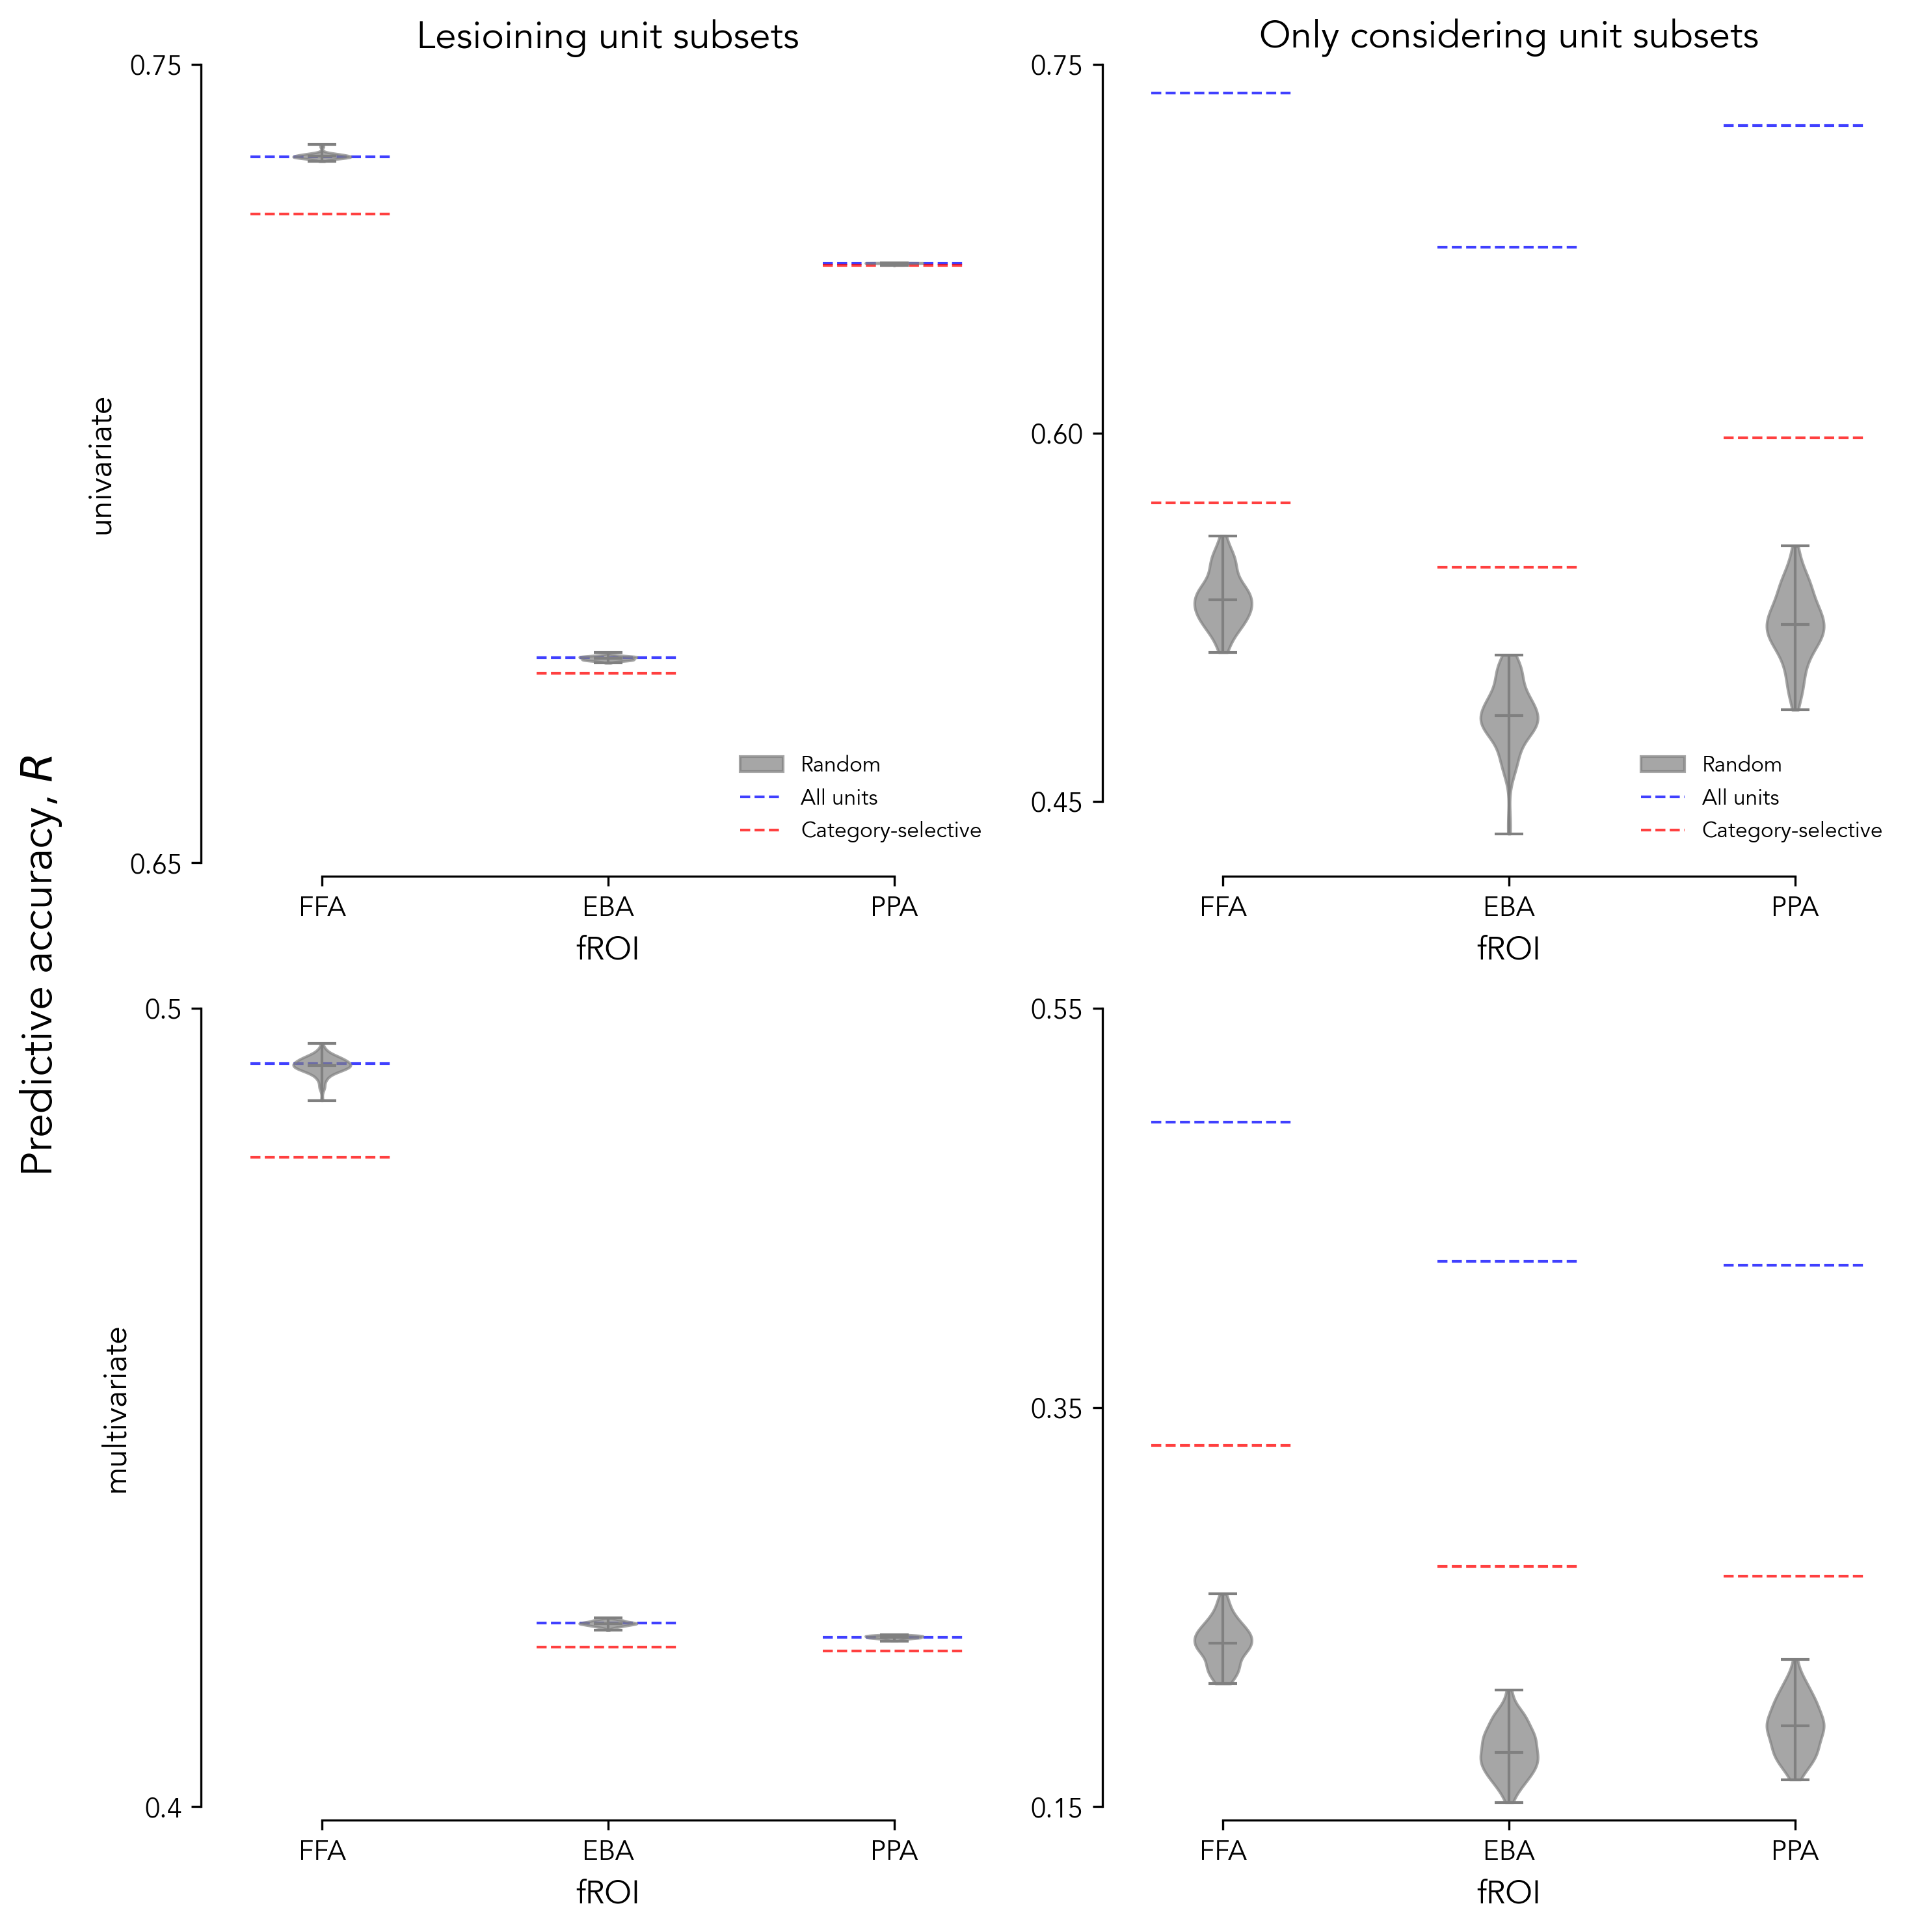

In [75]:
savefig = False

to_model_names = ma.get_model_names('task_optimized')
models_considered = to_model_names
print(f'{len(models_considered)} Models considered')

catsel_lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(catsel_lesion_csv_path)
random_lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha_randomsubsets_100bootstraps.csv'
random_lesion_csv = pd.read_csv(random_lesion_csv_path)

catsel_lesion_df = lesion_csv.copy()
random_lesion_df = random_lesion_csv.copy()
frois = ['FFA', 'EBA', 'PPA']
t_threshold = 7
mapper = 'ridge'
alpha = 0.1
subjects = [1, 2, 5, 7]
metrics = ['raw_pearsonr', 'raw_rdmr']
plot_ceiling = False

# Subset and take median across subjects for each model, fmri_froi
catsel_lesion_df = catsel_lesion_df[
    (catsel_lesion_df['model_tthreshold'] == t_threshold) &
    (catsel_lesion_df['fmri_tthreshold'] == t_threshold) &
    (catsel_lesion_df['mapper'] == mapper) &
    (catsel_lesion_df['alpha'] == alpha)
]
catsel_lesion_df_sbjmedian = catsel_lesion_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
	'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
}).reset_index()

random_lesion_df = random_lesion_df[
    (random_lesion_df['model_tthreshold'] == t_threshold) &
    (random_lesion_df['fmri_tthreshold'] == t_threshold) &
    (random_lesion_df['mapper'] == mapper) &
    (random_lesion_df['alpha'] == alpha)
]
random_lesion_df_sbjmedian = random_lesion_df.groupby(
    ['bootstrap_index', 'model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
    'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
}).reset_index()


fig, axs = plt.subplots(len(metrics), 2, figsize=(5*2, 5*len(metrics)), dpi=300)

# plot_lims_dict = {
#     'raw_pearsonr': {
#         0: { # For lesioin vs layer plot
#             'lims': (0.67, 0.815),
#             'ticks': [0.7, 0.8]
#         },
#         1: { # For fROI vs layer plot
#             'lims': (0.4, 0.815),
#             'ticks': [0.4, 0.6, 0.8]
#         }
#     },
#     'raw_rdmr': {
#         0: { # For lesioin vs layer plot
#             'lims': (0.4, 0.55),
#             'ticks': [0.4, 0.55]
#         },
#         1: { # For fROI vs layer plot
#             'lims': (0.1, 0.6),
#             'ticks': [0.1, 0.35, 0.6]
#         }
#     },
# }
# No ceiling for these plots
plot_lims_dict = {
    'raw_pearsonr': {
        0: { # For lesioin vs layer plot
            'lims': (0.65, 0.75),
            'ticks': [0.65, 0.75]
        },
        1: { # For fROI vs layer plot
            'lims': (0.425, 0.75),
            'ticks': [0.45, 0.6, 0.75]
        }
    },
    'raw_rdmr': {
        0: { # For lesioin vs layer plot
            'lims': (0.4, 0.5),
            'ticks': [0.4, 0.5]
        },
        1: { # For fROI vs layer plot
            'lims': (0.15, 0.55),
            'ticks': [0.15, 0.35, 0.55]
        }
    },
}

dx = 0.25

for fidx, froi in enumerate(frois):
    catsel_lesion_df_sbjmedian_froi = catsel_lesion_df_sbjmedian[catsel_lesion_df_sbjmedian['fmri_froi'] == froi]
    random_lesion_df_sbjmedian_froi = random_lesion_df_sbjmedian[random_lesion_df_sbjmedian['fmri_froi'] == froi]
    catsel_lesion_df_sbjmedian_froi_mdlmedian = catsel_lesion_df_sbjmedian_froi.groupby(
        ['fmri_froi']
    ).agg({
        'layer_raw_pearsonr': 'median',
        'layer_raw_rdmr': 'median',
        'froi_raw_pearsonr': 'median',
        'froi_raw_rdmr': 'median',
        'lesion_raw_pearsonr': 'median',
        'lesion_raw_rdmr': 'median',
    }).reset_index()
    random_lesion_df_sbjmedian_froi_mdlmedian = random_lesion_df_sbjmedian_froi.groupby(
        ['bootstrap_index', 'fmri_froi']
    ).agg({
        'layer_raw_pearsonr': 'median',
        'layer_raw_rdmr': 'median',
        'froi_raw_pearsonr': 'median',
        'froi_raw_rdmr': 'median',
        'lesion_raw_pearsonr': 'median',
        'lesion_raw_rdmr': 'median',
    }).reset_index()
    for midx, metric in enumerate(metrics):
        ceiling_y = np.median(catsel_lesion_df[
            (catsel_lesion_df['fmri_froi'] == froi)
        ]['fmri_splithalf_' + metric.split('_')[-1]].unique())
        allunits_y = catsel_lesion_df_sbjmedian_froi_mdlmedian[f'layer_{metric}'].values[0]
        catsel_lesion_y = catsel_lesion_df_sbjmedian_froi_mdlmedian[f'lesion_{metric}'].values[0]
        random_lesion_pts = np.array(random_lesion_df_sbjmedian_froi_mdlmedian[f'lesion_{metric}'].values)
        catsel_froi_y = catsel_lesion_df_sbjmedian_froi_mdlmedian[f'froi_{metric}'].values[0]
        random_froi_y = np.array(random_lesion_df_sbjmedian_froi_mdlmedian[f'froi_{metric}'].values)
        
        # Column 1: lesion vs layer
        ax_current = axs[midx, 0]
        # Create a violin plot at x=fidx with the random lesion points. Also make lines for ceiling, all units, and category-selective lesion
        parts = ax_current.violinplot(
            random_lesion_pts, positions=[fidx], widths=0.2, showmeans=False, showmedians=True,
        )
        if fidx == 0 and midx == 0:
            parts['bodies'][0].set_label('Random')
        for pc in parts['bodies']:
            pc.set_facecolor('gray')
            pc.set_edgecolor('gray')
            pc.set_alpha(0.7)
            pc.set_linewidth(1)
        for key in ['cmedians', 'cmins', 'cmaxes', 'cbars']:
            if key in parts:
                parts[key].set_color('gray')
                parts[key].set_linewidth(1)
        if plot_ceiling:
            ax_current.hlines(
                ceiling_y, fidx - dx, fidx + dx,
                colors='k', linestyles='--', alpha=0.75, linewidth=1, zorder=0,
                label='Ceiling' if fidx == 0 and midx == 0 else None
            )
        ax_current.hlines(
            allunits_y, fidx - dx, fidx + dx,
            colors='blue', linestyles='--', alpha=0.75, linewidth=1, zorder=0,
            label='All units' if fidx == 0 and midx == 0 else None
        )
        ax_current.hlines(
            catsel_lesion_y, fidx - dx, fidx + dx,
            colors='red', linestyles='--', alpha=0.75, linewidth=1, zorder=0,
            label='Category-selective' if fidx == 0 and midx == 0 else None
        )
        
        # Column 2: fROI vs layer
        ax_current = axs[midx, 1]
        parts = ax_current.violinplot(
            random_froi_y, positions=[fidx], widths=0.2, showmeans=False, showmedians=True
        )
        if fidx == 0 and midx == 0:
            parts['bodies'][0].set_label('Random')
        for pc in parts['bodies']:
            pc.set_facecolor('gray')
            pc.set_edgecolor('gray')
            pc.set_alpha(0.7)
            pc.set_linewidth(1)
        for key in ['cmedians', 'cmins', 'cmaxes', 'cbars']:
            if key in parts:
                parts[key].set_color('gray')
                parts[key].set_linewidth(1)
        if plot_ceiling:
            ax_current.hlines(
                ceiling_y, fidx - dx, fidx + dx,
                colors='k', linestyles='--', alpha=0.75, linewidth=1, zorder=0,
                label='Ceiling' if fidx == 0 and midx == 0 else None
            )
        ax_current.hlines(
            allunits_y, fidx - dx, fidx + dx,
            colors='blue', linestyles='--', alpha=0.75, linewidth=1, zorder=0,
            label='All units' if fidx == 0 and midx == 0 else None
        )
        ax_current.hlines(
            catsel_froi_y, fidx - dx, fidx + dx,
            colors='red', linestyles='--', alpha=0.75, linewidth=1, zorder=0,
            label='Category-selective' if fidx == 0 and midx == 0 else None
        )

metric_ylabels = {
    'raw_pearsonr': 'univariate',
    'raw_rdmr': 'multivariate',
}

for midx, metric in enumerate(metrics):
    for cidx, _ in enumerate(['lesion', 'froi']):
        ax_current = axs[midx, cidx]
        ax_current.set_xlabel('fROI', fontsize=12)
        if cidx == 0:
            ax_current.set_ylabel(metric_ylabels[metric], fontsize=12)
        if midx == 0:
            ax_current.legend(frameon=False, loc='lower right', fontsize=8)
            if cidx == 0:
                ax_current.set_title('Lesioining unit subsets', fontsize=14)
            else:
                ax_current.set_title('Only considering unit subsets', fontsize=14)
        ax_current.set_ylim(plot_lims_dict[metric][cidx]['lims'])
        ax_current.set_yticks(plot_lims_dict[metric][cidx]['ticks'])
        ax_current.set_xticks(range(len(frois)), frois)
        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['bottom'].set_position(('outward', 5))
        ax_current.spines['bottom'].set_bounds(0, len(frois)-1)
        ax_current.spines['left'].set_position(('outward', 5))
        ax_current.spines['left'].set_bounds(
            np.min(plot_lims_dict[metric][cidx]['ticks']), np.max(plot_lims_dict[metric][cidx]['ticks'])
        )
        # ax_current.set_xlim(0, 1)

fig.supylabel(r'Predictive accuracy, $R$', fontsize=16)
plt.tight_layout()
if savefig:
    raise NotImplementedError('Change plot name')
    # plt.savefig(f'{plot_dir}/figS11_lesion_randomsubsets_ridge.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:    
    plt.show()
plt.close()

In [ ]:
savefig = False
hide_y_info = False # Hide y-axis label and tick labels
figname = 'figS15_deltas_random_subsets.pdf'

category_colors = {
    'faces': '#4C78A8', # '#f09678',
    'scenes': '#F58518', # '#a6d2e5',
    'bodies': '#54A24B', # '#a7d6a1',
}
markersize = 8
comparison_marker_info = {
    'animal_vs_human_faces': {
        'markercolor': category_colors['faces'],
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'human_bodies_vs_human_faces': {
        'markercolor': 'none',
        'ec': category_colors['faces'], 'mew': 2, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'limbs_covered_vs_limbs_visible': {
        'markercolor': category_colors['bodies'],
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'animal_bodies_vs_human_bodies': {
        'markercolor': 'none',
        'ec': category_colors['bodies'], 'mew': 2, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'without_humans_vs_with_humans': {
        'markercolor': category_colors['scenes'],
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'low_vs_high_navigational_affordance': {
        'markercolor': 'none',
        'ec': category_colors['scenes'], 'mew': 2, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'random': {
        'markercolor': 'gray',
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 0.5, 'markersize': markersize/1.5, 'zorder': 5
    },
}

# Processing FFA...
# Minimum and maximum mean delta across subjects and models for FFA: -0.42688684128571425, 2.9752473714285714


# Processing EBA...
# Minimum and maximum mean delta across subjects and models for EBA: -1.8798262614285715, 1.691197050714286


# Processing PPA...
# Minimum and maximum mean delta across subjects and models for PPA: -1.05605245, 0.3201884743857143

fig, axes = plt.subplots(1, len(frois), figsize=(4*len(frois), 5), constrained_layout=True)
plot_limits_dict = { # Keep it the same for plot 0 and 1 to allow slope interpretation,
    # For ylims, add a 1% offset to min to give some space below the lowest point, and set the max to accommodate the highest point across both plots
    'lim': {
        'FFA': [-0.5, 3.25],
        'EBA': [-2, 1.75],
        'PPA': [-1.5, 0.5], 
    }, # all min y-lims have a 0.05 offset to give some space below the lowest point, and all max y-lims are set to accommodate the highest point across both plots
    'ticks': {'FFA': np.array([-0.5, 0, 3.25]),'EBA': np.array([-2, 0, 1.75]),'PPA': np.array([-1.5, 0, 0.5])},
}

for froi_idx, froi in enumerate(frois):
    print(f'Processing {froi}...')
    ax_current = axes[froi_idx]
    ax_current.set_aspect('equal', adjustable='box') # Set aspect ratio to 1:1 to make the slope visually interpretable
    froi_deltas_df = all_bags_deltas_df[all_bags_deltas_df['froi'] == froi]
    # Figure out plot limits across all models and subjects for this froi to set the same limits for the successful, extra, and random bags plots to allow visual slope comparison
    print(f'Minimum and maximum mean delta across subjects and models for {froi}: {froi_deltas_df[["subjects_delta_mean", "models_delta_mean"]].min().min()}, {froi_deltas_df[["subjects_delta_mean", "models_delta_mean"]].max().max()}')
    for row_idx, row in froi_deltas_df.iterrows():
        hypothesis_label = row['hypothesis']
        comparison_label = row['comparison']
        comparison_label_str = None
        if comparison_label.startswith('bag1_vs_bag2'):
            if comparison_label == 'bag1_vs_bag2_idx=0':
                comparison_label_str = 'random'
        else:
            comparison_label_str = comparison_label
        if comparison_label_str is None:
            marker_kwargs = comparison_marker_info['random']
        else:
            marker_kwargs = comparison_marker_info[comparison_label_str]
        ax_current.plot(
            row['models_delta_mean'], row['subjects_delta_mean'], linestyle='None',
            marker=marker_kwargs['marker'], color=marker_kwargs['markercolor'], alpha=marker_kwargs['alpha'],
            markersize=marker_kwargs['markersize'],
            mec=marker_kwargs['ec'], mew=marker_kwargs['mew'],
            label=comparison_label_str,
            zorder=marker_kwargs['zorder']
        )
    # Plot x=0, y=0, and y=x lines to help visually compare the slopes across the successful, extra, and random bags
    ax_current.axhline(
            y=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.axvline(
            x=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.plot(
            plot_limits_dict['lim'][froi], plot_limits_dict['lim'][froi], color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.set_xlabel('Model response difference\n(median across top-10 models)')
    if hide_y_info:
        ax_current.set_yticklabels([])
        ax_current.set_ylabel('')
    else:
        ax_current.set_ylabel('Brain response difference')
    # ax_current.set_title(f'{froi} - Subject vs. Model Deltas')
    if froi_idx == 0: # Only add legend to the first plot to avoid redundancy, since the same color scheme is used across all plots
        ax_current.legend(frameon=False, loc='upper left', fontsize=8)
    ax_current.text(0.85, 0.1, froi, transform=ax_current.transAxes, fontsize=12, verticalalignment='top')
    ax_current.set_ylim(plot_limits_dict['lim'][froi])
    ax_current.set_yticks(plot_limits_dict['ticks'][froi])
    ax_current.set_xticks(plot_limits_dict['ticks'][froi])
    ax_current.spines['top'].set_visible(False)
    ax_current.spines['right'].set_visible(False)
    ax_current.spines['bottom'].set_position(('outward', 5))
    ax_current.spines['bottom'].set_bounds((np.min(plot_limits_dict['ticks'][froi]), np.max(plot_limits_dict['ticks'][froi])))
    ax_current.spines['left'].set_position(('outward', 5))
    ax_current.spines['left'].set_bounds((np.min(plot_limits_dict['ticks'][froi]), np.max(plot_limits_dict['ticks'][froi])))
    ax_current.set_xlim(plot_limits_dict['lim'][froi])
    print('\n')

# plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
plt.show()
print('\n\n')